# 5강. 대표 모델과 전이학습: 남이 학습한 모델을 내 문제에 맞추기

**저자**: 이창민 · **라이선스**: 본문 CC BY 4.0, 코드 MIT (제3자 자료 제외, NOTICE 참고)

**대상**: 파이썬과 1~4강 내용을 아는 입문자 · **분량**: 6부 · **환경**: Google Colab

이 강의 목표는 **자신의 목적에 맞게 네트워크를 고쳐 쓰는 것**입니다. 끝나면 다음을 할 수 있습니다.

- AlexNet, GoogLeNet, VGG, ResNet, EfficientNet이 각각 어떤 문제를 풀었는지 설명하고 직접 구현한다.
- `torchvision.models`에서 사전학습 모델을 불러와 쓴다.
- pickle, `torch.save`, TorchScript, safetensors의 차이를 알고, 체크포인트로 학습을 이어 간다.
- `requires_grad`로 일부 층을 동결하고, 출력층을 바꿔 전이학습을 한다.
- 파인튜닝과 특징 추출을 구분해 작은 데이터셋(개미/벌)에 적용한다.
- `timm`으로 ConvNeXt, DINOv2 같은 현재의 백본을 가져와 쓴다.

| 부 | 주제 | 다루는 내용 |
|---|---|---|
| 1부 | 대표 모델 | `torchvision.models`, AlexNet, GoogLeNet, VGG, ResNet |
| 2부 | 직접 학습하기 | CIFAR-10으로 VGG16과 ResNet50 학습 |
| 3부 (선택) | EfficientNet | 복합 스케일링, MBConv, SE 블록, STL10 학습 |
| 4부 | 모델 저장과 불러오기 | pickle, `torch.save`, TorchScript, safetensors, 체크포인트 |
| 5부 | 동결과 전이학습 | Freeze, 출력층 교체, 입력층 교체, 학습률 나누기, 다른 손글씨 데이터 |
| 6부 | 파인튜닝 실습 | 개미/벌 분류: 파인튜닝 vs 특징 추출, 현재의 백본 고르기 |

> **필수와 선택**: 3부만 선택이고 나머지는 필수입니다.
>
> **사용법**: 위에서 아래로 순서대로 실행하세요. 메뉴의 `런타임 → 런타임 유형 변경`에서 **T4 GPU**를 고르면 학습이 빨라집니다. `실습` 셀은 직접 채우고, 막히면 아래의 `정답`을 펼쳐 보세요. `답`이 붙은 질문은 먼저 생각해 본 뒤 펼치세요.
>
> **용량 주의**: 3부의 STL10은 압축 파일만 약 2.6GB입니다. 받는 데 시간이 걸리니, 3부를 건너뛰고 싶으면 그 부의 셀만 실행하지 마세요. 뒤의 부는 3부에 의존하지 않습니다.
>
> **예상 시간**: 읽고 실습까지 6~8시간(어림값)입니다. 실행 시간은 이 교재를 검증한 Mac(MPS, 다른 작업과 함께 실행)에서 저장된 축소 설정으로 약 28분이었습니다. 원래 설정 그대로면 저장된 출력으로 환산해 VGG 약 30분, ResNet 약 40분, EfficientNet 약 30분이 더 걸려 전체가 2시간 남짓입니다. Colab에서는 재 보지 않았습니다. 시간이 부족하면 부별 에폭 변수 `num_epoch`(2부), `TRIAL_EPOCHS`와 `EFF_EPOCHS`(3부), `EPOCHS`와 `epochs`(4, 5부), `epoch_length`(5부)를 줄이세요.
>
> **막혔을 때**: 에러 메시지의 마지막 줄을 [PyTorch 포럼](https://discuss.pytorch.org/)에서 검색해 보세요. 모델과 입력이 같은 장치에 있는지, 크기가 맞는지부터 확인하면 대부분 풀립니다.

In [1]:
# 이 강의 전체에서 쓰는 라이브러리
%pip install -q safetensors timm torchinfo

import contextlib
import copy
import io
import json
import math
import os

# timm이 가중치를 받을 때 진행 표시를 길게 출력하지 않게 합니다
os.environ["HF_HUB_DISABLE_PROGRESS_BARS"] = "1"

import pickle
import random
import struct
import subprocess
import sys
import time
import urllib.request
import warnings
import zipfile
from pathlib import Path
from typing import Callable

import matplotlib.pyplot as plt
import numpy as np
import timm
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
import torchvision
from safetensors.torch import load_file, load_model, save_model
from torch.optim import lr_scheduler
from torch.utils.data import DataLoader, Subset, random_split
from torchinfo import summary
from torchvision import datasets, models, utils
from torchvision.transforms import v2 as transforms

device = torch.device("cuda" if torch.cuda.is_available() else "mps" if torch.backends.mps.is_available() else "cpu")
print("PyTorch:", torch.__version__, "/ torchvision:", torchvision.__version__, "/ device:", device)


def set_seed(seed: int = 1729) -> None:
    """파이썬, NumPy, PyTorch의 난수를 한 번에 고정합니다. 1강에서 만든 함수입니다."""
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)


def count_params(model: nn.Module) -> int:
    """모델의 전체 파라미터 수를 셉니다."""
    return sum(p.numel() for p in model.parameters())


def count_trainable(model: nn.Module) -> int:
    """requires_grad가 켜진, 실제로 학습되는 파라미터 수만 셉니다."""
    return sum(p.numel() for p in model.parameters() if p.requires_grad)


set_seed()

# PIL 이미지를 [0, 1] 범위의 텐서로 바꿉니다
TO_TENSOR = transforms.Compose([transforms.ToImage(), transforms.ToDtype(torch.float32, scale=True)])

Note: you may need to restart the kernel to use updated packages.


PyTorch: 2.15.0 / torchvision: 0.29.2 / device: mps


---
# 1부. 대표 모델 살펴보기

전이학습은 "남이 학습해 둔 모델을 가져와 고쳐 쓰는 일"입니다. 무엇을 가져올지 고르려면 대표 모델들이 어떤 문제를 어떻게 풀었는지 알아야 합니다.

## 1.1 `torchvision.models`

사전학습 모델은 `torchvision.models`에 기본으로 들어 있습니다. 어떤 이름이 있는지 파이썬의 `dir()`로 확인할 수 있습니다. `dir()`은 객체가 가진 속성의 이름을 모두 돌려주는 함수입니다. 정수 하나에도 많은 속성이 있습니다.

In [2]:
x = 1
print(len(dir(x)), "개의 속성 중 앞의 몇 개:", dir(x)[:5], "...", dir(x)[-4:])

74 개의 속성 중 앞의 몇 개: ['__abs__', '__add__', '__and__', '__bool__', '__ceil__'] ... ['is_integer', 'numerator', 'real', 'to_bytes']


In [3]:
# torchvision에서 제공하는 기본 모델 확인하기
names = [name for name in dir(models) if not name.startswith("_")]
weight_names = [name for name in names if name.endswith("_Weights")]
print("전체 이름:", len(names), "/ 그중 ~_Weights:", len(weight_names))
print(", ".join(weight_names[:12]), "...")

전체 이름: 208 / 그중 ~_Weights: 80
AlexNet_Weights, ConvNeXt_Base_Weights, ConvNeXt_Large_Weights, ConvNeXt_Small_Weights, ConvNeXt_Tiny_Weights, DenseNet121_Weights, DenseNet161_Weights, DenseNet169_Weights, DenseNet201_Weights, EfficientNet_B0_Weights, EfficientNet_B1_Weights, EfficientNet_B2_Weights ...


이름 끝이 `_Weights`인 것은 **해당 모델의 사전학습 파라미터 목록**입니다. 소문자 이름(`alexnet`)은 모델을 만들어 주는 함수이고, 대문자로 시작하는 이름(`AlexNet`)은 모델 클래스입니다. 사전학습 가중치는 **소문자 함수**에 넘깁니다.

```python
weights = models.AlexNet_Weights.DEFAULT
model = models.alexnet(weights=weights)
```

클래스인 `models.AlexNet`에 `weights=`를 넘기면 에러가 납니다. 인터넷의 예제에서 자주 보이는 실수이니 한 번 확인해 둡시다.

In [4]:
try:
    models.AlexNet(weights=models.AlexNet_Weights.DEFAULT)
except TypeError as error:
    print("TypeError:", error)

weights = models.AlexNet_Weights.DEFAULT
pretrained_alexnet = models.alexnet(weights=weights)   # 처음 실행하면 가중치 파일(약 233MB)을 받습니다
print(pretrained_alexnet(torch.zeros(1, 3, 224, 224)).shape, "/ 가중치 이름:", weights)
print("ImageNet 클래스 수:", len(weights.meta["categories"]), "/ 예:", weights.meta["categories"][:3])

TypeError: AlexNet.__init__() got an unexpected keyword argument 'weights'
torch.Size([1, 1000]) / 가중치 이름: AlexNet_Weights.IMAGENET1K_V1
ImageNet 클래스 수: 1000 / 예: ['tench', 'goldfish', 'great white shark']


`weights.meta`에는 파라미터 수와 ImageNet 정확도가 들어 있습니다. 파일을 받지 않고도 읽을 수 있으니, 이 강에서 볼 모델들을 한 그래프에 놓아 봅시다. 뒤의 설명을 읽으면서 이 그래프로 돌아와 보세요. 위로 갈수록 정확하고, 왼쪽으로 갈수록 가볍습니다. 초록 점 ConvNeXt는 6부에서 직접 써 봅니다. 입력 크기와 학습 방법이 모델마다 달라 정확한 순위가 아니라 큰 흐름으로 읽으세요.

model             year  params(M)  top-1(%)
AlexNet           2012       61.1     56.52
GoogLeNet         2014        6.6     69.78
VGG16             2014      138.4     71.59
ResNet18          2015       11.7     69.76
ResNet50          2015       25.6     76.13
ResNet152         2015       60.2     78.31
EfficientNet-B0   2019        5.3     77.69
EfficientNet-B3   2019       12.2     82.01
EfficientNet-B7   2019       66.3     84.12
ConvNeXt-Tiny     2022       28.6     82.52
ConvNeXt-Base     2022       88.6     84.06


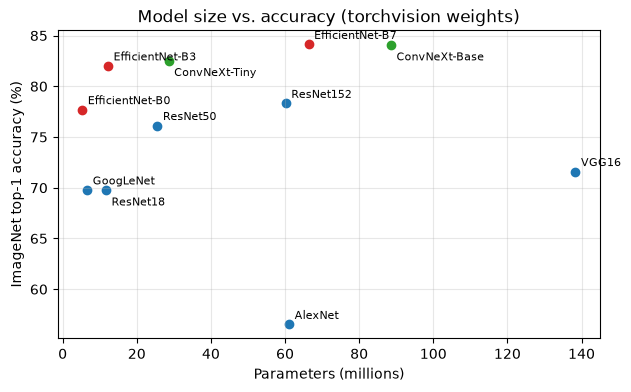

In [5]:
# 가중치 세대를 맞추려고 모두 IMAGENET1K_V1을 씁니다
MODEL_ZOO = [
    ("AlexNet", 2012, models.AlexNet_Weights.IMAGENET1K_V1),
    ("GoogLeNet", 2014, models.GoogLeNet_Weights.IMAGENET1K_V1),
    ("VGG16", 2014, models.VGG16_Weights.IMAGENET1K_V1),
    ("ResNet18", 2015, models.ResNet18_Weights.IMAGENET1K_V1),
    ("ResNet50", 2015, models.ResNet50_Weights.IMAGENET1K_V1),
    ("ResNet152", 2015, models.ResNet152_Weights.IMAGENET1K_V1),
    ("EfficientNet-B0", 2019, models.EfficientNet_B0_Weights.IMAGENET1K_V1),
    ("EfficientNet-B3", 2019, models.EfficientNet_B3_Weights.IMAGENET1K_V1),
    ("EfficientNet-B7", 2019, models.EfficientNet_B7_Weights.IMAGENET1K_V1),
    ("ConvNeXt-Tiny", 2022, models.ConvNeXt_Tiny_Weights.IMAGENET1K_V1),
    ("ConvNeXt-Base", 2022, models.ConvNeXt_Base_Weights.IMAGENET1K_V1),
]

fig, ax = plt.subplots(figsize=(7, 4))
print(f"{'model':16s} {'year':>5s} {'params(M)':>10s} {'top-1(%)':>9s}")
for name, year, zoo_weights in MODEL_ZOO:
    params_m = zoo_weights.meta["num_params"] / 1e6
    top1 = zoo_weights.meta["_metrics"]["ImageNet-1K"]["acc@1"]
    print(f"{name:16s} {year:5d} {params_m:10.1f} {top1:9.2f}")
    ax.scatter(params_m, top1, color="tab:red" if "Efficient" in name else "tab:green" if "ConvNeXt" in name else "tab:blue")
    # 정확도와 크기가 가까운 모델은 글자가 겹치므로 일부를 아래로 내립니다
    offset = (4, -11) if name in {"ResNet18", "ConvNeXt-Tiny", "ConvNeXt-Base"} else (4, 4)
    ax.annotate(name, (params_m, top1), xytext=offset, textcoords="offset points", fontsize=8)
ax.set_xlabel("Parameters (millions)")
ax.set_ylabel("ImageNet top-1 accuracy (%)")
ax.set_title("Model size vs. accuracy (torchvision weights)")
ax.grid(alpha=0.3)
plt.show()

일단은 각 모델의 구조와 코드를 알아본 뒤, 쉽게 가져다 쓰겠습니다.

## 1.2 AlexNet

2012년 ILSVRC(ImageNet Large Scale Visual Recognition Challenge) 대회에서 우승한 CNN입니다. CNN이 다시 주목받는 데 아주 큰 역할을 했습니다. 논문이 시도한 것은 다음과 같습니다.

1. **GPU 2개 사용**: 2012년의 GPU는 메모리가 부족해 채널을 절반씩 두 GPU에 나눠 학습하고, 3번째 합성곱 층 등 일부 층에서만 두 GPU가 정보를 주고받았습니다.
2. **Data augmentation**: 이미지를 자르고 뒤집어 데이터를 늘렸습니다.
3. **Dropout**: 완전 연결 층의 과적합을 줄였습니다.
4. **Overlapping Pooling**: 커널 3, 스트라이드 2로 풀링 영역을 겹쳤습니다.
5. **Local Response Normalization**: 지금은 BatchNorm에 자리를 내줘 거의 쓰지 않습니다. 아래 구현에서도 뺐습니다.
6. **Non-saturating activation, ReLU**: 논문은 4층 CNN으로 CIFAR-10의 학습 오차 25%에 도달하는 데 ReLU가 tanh보다 **6배 빠르다**는 그래프를 실었습니다. tanh는 입력이 크면 기울기가 0에 가까워지지만(포화) ReLU는 양수 쪽에서 포화하지 않기 때문입니다.

구조 그림은 [여기](https://i.imgur.com/OIyNuVv.png), ReLU와 tanh 비교 그림은 [여기](https://img1.daumcdn.net/thumb/R1280x0/?scode=mtistory2&fname=https%3A%2F%2Fblog.kakaocdn.net%2Fdn%2FrVvBs%2FbtrKz4ctVae%2F6CanCrkGV3gTKpZ91rcyrk%2Fimg.png)에서 볼 수 있습니다.

> 논문 그림에는 입력이 224로 적혀 있지만, 첫 층(커널 11, 스트라이드 4, 패딩 0)이 55를 만들려면 계산상 227이어야 합니다. 그래서 흔히 227로 구현합니다. `torchvision`은 입력 224에 패딩 2를 써서 같은 55를 만듭니다. 아래 식으로 직접 계산해 보세요.

합성곱 뒤 크기는 다음 식으로 구합니다 (W: 입력 크기, F: 커널, P: 패딩, S: 스트라이드).

$$W' = \left\lfloor \frac{W - F + 2P}{S} \right\rfloor + 1$$

In [6]:
class AlexNet(nn.Module):
    """논문의 합성곱 5층과 완전 연결 3층을 한 줄씩 쌓았습니다. 입력은 3x227x227입니다. LRN은 생략했습니다."""

    def __init__(self, num_classes: int = 10) -> None:
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(3, 96, kernel_size=11, stride=4),   # (227 - 11) / 4 + 1 = 55
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=3, stride=2),        # (55 - 3) / 2 + 1 = 27
            # 논문의 "커널 48개"는 GPU 2대에 96개를 절반씩 나눈 수입니다. 한 번에 구현하면 96입니다.
            nn.Conv2d(96, 256, kernel_size=5, padding=2),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=3, stride=2),        # 27 -> 13
            nn.Conv2d(256, 384, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.Conv2d(384, 384, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.Conv2d(384, 256, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=3, stride=2),        # 13 -> 6
        )
        # Dropout을 모듈로 두어야 model.eval()에 따라 꺼집니다
        self.classifier = nn.Sequential(
            nn.Linear(256 * 6 * 6, 4096), nn.ReLU(), nn.Dropout(0.5),
            nn.Linear(4096, 4096), nn.ReLU(), nn.Dropout(0.5),
            nn.Linear(4096, num_classes),   # CrossEntropyLoss 안에 softmax가 있으니 로짓 그대로 냅니다
        )

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        return self.classifier(self.features(x).flatten(start_dim=1))


alexnet = AlexNet()
x = torch.zeros(2, 3, 227, 227)
for layer in alexnet.features:
    x = layer(x)
    if not isinstance(layer, nn.ReLU):   # 크기가 바뀌는 층만 보여 줍니다
        print(f"{type(layer).__name__:10s}", tuple(x.shape))
print("파라미터 수:", f"{count_params(alexnet):,}")

Conv2d     (2, 96, 55, 55)
MaxPool2d  (2, 96, 27, 27)
Conv2d     (2, 256, 27, 27)
MaxPool2d  (2, 256, 13, 13)
Conv2d     (2, 384, 13, 13)
Conv2d     (2, 384, 13, 13)
Conv2d     (2, 256, 13, 13)
MaxPool2d  (2, 256, 6, 6)
파라미터 수: 58,322,314


AlexNet 구현을 인터넷에서 찾아 읽다 보면 자주 만나는 함정이 있습니다.

- `F.dropout(out, 0.5)`는 `training` 인자의 기본값이 `True`라 `model.eval()`을 해도 계속 동작합니다. 같은 입력의 예측이 매번 달라집니다.
- 마지막의 `F.log_softmax`는 `nn.CrossEntropyLoss`와 중복입니다 (`nn.NLLLoss`와 짝을 이룹니다).
- 논문 그림의 커널 48개를 드롭아웃 때문이라고 설명하는 글도 있지만, 실제 이유는 GPU 2대입니다.

첫 번째 함정을 직접 확인해 봅시다.

In [7]:
class BadDropout(nn.Module):
    def forward(self, x: torch.Tensor) -> torch.Tensor:
        return F.dropout(x, 0.5)   # training 인자를 넘기지 않음


bad, good = BadDropout().eval(), nn.Dropout(0.5).eval()
sample = torch.ones(1, 6)
print("F.dropout, eval 모드:", bad(sample).tolist())
print("nn.Dropout, eval 모드:", good(sample).tolist())

F.dropout, eval 모드: [[2.0, 0.0, 0.0, 2.0, 2.0, 2.0]]
nn.Dropout, eval 모드: [[1.0, 1.0, 1.0, 1.0, 1.0, 1.0]]


`torchvision`이 쓰는 AlexNet은 [공식 코드](https://pytorch.org/vision/main/_modules/torchvision/models/alexnet.html)에서 볼 수 있습니다. [이 글](https://ingu627.github.io/code/alexnet_pytorch/)도 참고했습니다.

## 1.3 GoogLeNet

**Inception 모듈**로 AlexNet보다 훨씬 깊으면서도 파라미터는 논문 기준 약 1/12(약 500만 개)로 줄인 모델입니다. 2014년 ILSVRC 분류 부문 우승 모델입니다. 빽빽한 완전 연결 구조 대신 성긴(sparse) 연결 구조를 씁니다.

Inception 모듈은 입력에 **1x1, 3x3, 5x5 합성곱과 3x3 풀링을 나란히 적용한 뒤 채널 방향으로 이어 붙입니다**. 그래서 여러 스케일의 특징을 동시에 뽑습니다. 그대로 하면 채널이 불어나 계산량이 폭발하므로, 3x3과 5x5 앞과 풀링 뒤에 **1x1 합성곱을 넣어 채널을 줄입니다**. 아래 그림의 왼쪽이 단순한 버전, 오른쪽이 차원 축소를 넣은 버전입니다. 논문 그림은 [여기](https://velog.velcdn.com/images%2Fwoojinn8%2Fpost%2F2531811b-1ed9-4544-b23a-d66556fb3637%2Finception_module.PNG)에 있습니다.

그 밖의 특징은 다음과 같습니다.

- 메모리 효율을 위해 초반에는 일반 합성곱을 쌓고, 뒤쪽에서 Inception 모듈을 씁니다.
- 기울기 소실을 줄이려고 네트워크 중간에 **보조 분류기(auxiliary classifier)** 2개를 붙여 추가로 역전파를 일으킵니다. 학습 때만 쓰고 추론 때는 버립니다. 전체 구조는 [이 그림](https://velog.velcdn.com/images%2Feuisuk-chung%2Fpost%2F67eeba16-0d25-4e52-a544-694169cd4c92%2Fimage.png)에서 볼 수 있습니다.

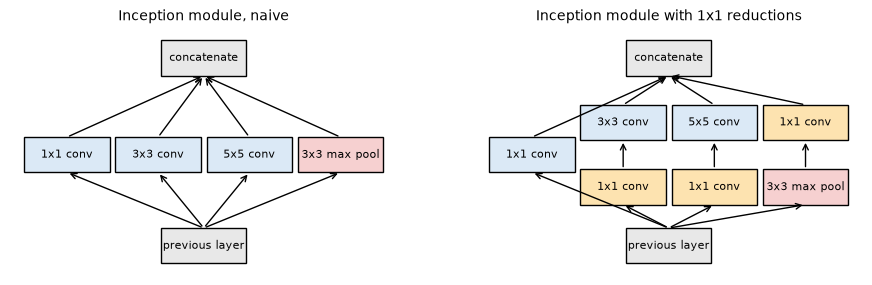

In [8]:
def draw_box(ax: plt.Axes, x: float, y: float, text: str, color: str = "#dbe9f6", width: float = 1.5) -> None:
    """텍스트가 든 상자를 그립니다. 이 강에서 그릴 구조도에서 함께 씁니다."""
    ax.add_patch(plt.Rectangle((x - width / 2, y - 0.3), width, 0.6, facecolor=color, edgecolor="black"))
    ax.text(x, y, text, ha="center", va="center", fontsize=8)


def draw_arrow(ax: plt.Axes, start: tuple[float, float], end: tuple[float, float]) -> None:
    ax.annotate("", xy=end, xytext=start, arrowprops=dict(arrowstyle="->", lw=1))


def draw_inception(ax: plt.Axes, title: str, reduce: bool) -> None:
    branches = [("1x1 conv", None), ("3x3 conv", "1x1 conv"), ("5x5 conv", "1x1 conv"), ("3x3 max pool", None)]
    draw_box(ax, 3.3, 0, "previous layer", "#e8e8e8")
    draw_box(ax, 3.3, 3.2, "concatenate", "#e8e8e8")
    for i, (main, before) in enumerate(branches):
        bx = 0.9 + i * 1.6
        if reduce and before:
            draw_box(ax, bx, 1, before, "#fde3b0")
            draw_arrow(ax, (3.3, 0.3), (bx, 0.7))
            draw_box(ax, bx, 2.1, main)
            draw_arrow(ax, (bx, 1.3), (bx, 1.8))
            draw_arrow(ax, (bx, 2.4), (3.3, 2.9))
        elif reduce and main == "3x3 max pool":
            draw_box(ax, bx, 1, main, "#f6d0d0")
            draw_arrow(ax, (3.3, 0.3), (bx, 0.7))
            draw_box(ax, bx, 2.1, "1x1 conv", "#fde3b0")
            draw_arrow(ax, (bx, 1.3), (bx, 1.8))
            draw_arrow(ax, (bx, 2.4), (3.3, 2.9))
        else:
            draw_box(ax, bx, 1.55, main, "#f6d0d0" if "pool" in main else "#dbe9f6")
            draw_arrow(ax, (3.3, 0.3), (bx, 1.25))
            draw_arrow(ax, (bx, 1.85), (3.3, 2.9))
    ax.set_xlim(-0.1, 6.7)
    ax.set_ylim(-0.5, 3.7)
    ax.set_title(title, fontsize=10)
    ax.axis("off")


fig, axes = plt.subplots(1, 2, figsize=(11, 3.2))
draw_inception(axes[0], "Inception module, naive", reduce=False)
draw_inception(axes[1], "Inception module with 1x1 reductions", reduce=True)
plt.show()

GoogLeNet을 구현해 봅시다. 네 갈래를 가진 Inception 모듈을 만들고, 논문의 표대로 쌓습니다. ([참고 글](https://velog.io/@euisuk-chung/%ED%8C%8C%EC%9D%B4%ED%86%A0%EC%B9%98-%ED%8C%8C%EC%9D%B4%ED%86%A0%EC%B9%98%EB%A1%9C-CNN-%EB%AA%A8%EB%8D%B8%EC%9D%84-%EA%B5%AC%ED%98%84%ED%95%B4%EB%B3%B4%EC%9E%90-GoogleNet%ED%8E%B8))

In [9]:
def conv_relu(in_channels: int, out_channels: int, kernel_size: int, stride: int = 1, padding: int = 0) -> nn.Sequential:
    return nn.Sequential(nn.Conv2d(in_channels, out_channels, kernel_size, stride, padding), nn.ReLU())


class Inception(nn.Module):
    """네 갈래를 나란히 돌려 채널 방향으로 잇습니다. 인자 이름은 논문 표의 열 이름을 따랐습니다."""

    def __init__(self, in_channels: int, c1: int, c3_reduce: int, c3: int, c5_reduce: int, c5: int, pool_proj: int) -> None:
        super().__init__()
        self.branches = nn.ModuleList([
            conv_relu(in_channels, c1, 1),
            nn.Sequential(conv_relu(in_channels, c3_reduce, 1), conv_relu(c3_reduce, c3, 3, padding=1)),
            nn.Sequential(conv_relu(in_channels, c5_reduce, 1), conv_relu(c5_reduce, c5, 5, padding=2)),
            nn.Sequential(nn.MaxPool2d(3, stride=1, padding=1), conv_relu(in_channels, pool_proj, 1)),
        ])

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        # 네 갈래 모두 가로세로를 유지하므로 이어 붙일 수 있습니다
        return torch.cat([branch(x) for branch in self.branches], dim=1)


# 논문 Table 1의 값입니다. 숫자 묶음은 Inception의 인자이고, "pool"은 크기를 절반으로 줄이는 풀링입니다.
INCEPTION_PLAN = [
    (192, 64, 96, 128, 16, 32, 32), (256, 128, 128, 192, 32, 96, 64), "pool",
    (480, 192, 96, 208, 16, 48, 64), (512, 160, 112, 224, 24, 64, 64), (512, 128, 128, 256, 24, 64, 64),
    (512, 112, 144, 288, 32, 64, 64), (528, 256, 160, 320, 32, 128, 128), "pool",
    (832, 256, 160, 320, 32, 128, 128), (832, 384, 192, 384, 48, 128, 128),
]


class GoogLeNet(nn.Module):
    """입력은 3x224x224입니다. 보조 분류기와 Local Response Normalization은 생략했습니다."""

    def __init__(self, num_classes: int = 2) -> None:
        super().__init__()
        self.stem = nn.Sequential(
            conv_relu(3, 64, 7, stride=2, padding=3),
            nn.MaxPool2d(3, stride=2, padding=1),
            conv_relu(64, 64, 1),   # 1x1로 채널을 정리한 뒤 3x3을 합니다
            conv_relu(64, 192, 3, padding=1),
            nn.MaxPool2d(3, stride=2, padding=1),
        )
        self.body = nn.Sequential(*[
            nn.MaxPool2d(3, stride=2, padding=1) if step == "pool" else Inception(*step) for step in INCEPTION_PLAN
        ])
        self.head = nn.Sequential(nn.AdaptiveAvgPool2d(1), nn.Flatten(), nn.Dropout(0.4), nn.Linear(1024, num_classes))

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        return self.head(self.body(self.stem(x)))


googlenet = GoogLeNet()
print("출력:", googlenet(torch.zeros(3, 3, 224, 224)).shape)
print("우리 구현:", f"{count_params(googlenet):,}", "/ AlexNet 대비", round(count_params(alexnet) / count_params(googlenet), 1), "분의 1")
print("출력을 1000개로 맞추면:", f"{count_params(GoogLeNet(num_classes=1000)):,}", "/", round(count_params(AlexNet(1000)) / count_params(GoogLeNet(num_classes=1000)), 1), "분의 1")

출력: torch.Size([3, 2])
우리 구현: 5,975,602 / AlexNet 대비 9.8 분의 1


출력을 1000개로 맞추면: 6,998,552 / 8.9 분의 1


논문의 12분의 1은 어림수입니다. 표대로 구현하면 ImageNet 기준(출력 1000개) 약 700만 개라 약 9분의 1이고, 맨 위 표의 `torchvision` 값도 비슷합니다. 자릿수가 하나 줄어든다는 점이 핵심입니다.

`torchvision`의 구조는 [공식 코드](https://pytorch.org/vision/main/_modules/torchvision/models/googlenet.html)에 있습니다. 여기에는 층마다 BatchNorm이 들어가고 보조 분류기가 붙어 파라미터 수가 다릅니다.

GoogLeNet을 직접 구현할 때 흔한 실수가 두 가지 있습니다. 첫 층의 합성곱 뒤에 활성화 함수를 빠뜨리는 것과, `forward`에서 전역 변수 `batch_size`를 읽어 배치 크기가 바뀌면 에러가 나는 것입니다.

## 1.4 VGG

**작은 필터로 층을 깊게 쌓은** 모델입니다. 논문은 2014년 ILSVRC 때 분류 부문 2위(오차 7.3%)였고, 제출 후 개선해 우승한 GoogLeNet(6.7%)과 거의 같은 6.8%를 보고했습니다. 구조가 훨씬 단순한데 오차 차이가 0.1%포인트밖에 나지 않아 큰 주목을 받았습니다. 깊이에 따라 VGG11, VGG13, VGG16, VGG19로 부릅니다. [구조 그림](https://img1.daumcdn.net/thumb/R1280x0/?scode=mtistory2&fname=https%3A%2F%2Fblog.kakaocdn.net%2Fdn%2FcvclSk%2FbtrF2Ne8qKG%2FKzDQiwpP0fSkaZvRdnCE1K%2Fimg.png)에서 합성곱 묶음마다 크기가 절반이 되고(224→112→56→28→14→7) 채널이 64→128→256→512→512로 늘어나는 모습을 볼 수 있습니다.

**Q. 왜 3x3만 사용했을까요?** 7x7을 쓰면 한 번에 넓은 범위를 볼 수 있어 좋을 것 같습니다.

<details><summary>답</summary>

3x3을 세 번 쌓으면 **보는 범위(수용 영역)는 7x7 한 번과 같습니다**. 그러면서 두 가지가 좋아집니다. 아래 그림을 먼저 보고 이어서 읽으세요.

1. **비선형성 증가**: 합성곱 뒤마다 ReLU가 붙습니다. 7x7 한 층은 비선형 함수를 한 번 지나지만 3x3 세 층은 세 번 지납니다. 그만큼 복잡한 경계를 표현할 수 있습니다.
2. **파라미터 감소**: 채널당 7x7 필터는 가중치가 49개이고, 3x3 필터 3개는 27개(3x3x3)입니다.

</details>

참고한 설명은 [이 글](https://medium.com/@msmapark2/vgg16-%EB%85%BC%EB%AC%B8-%EB%A6%AC%EB%B7%B0-very-deep-convolutional-networks-for-large-scale-image-recognition-6f748235242a)입니다.

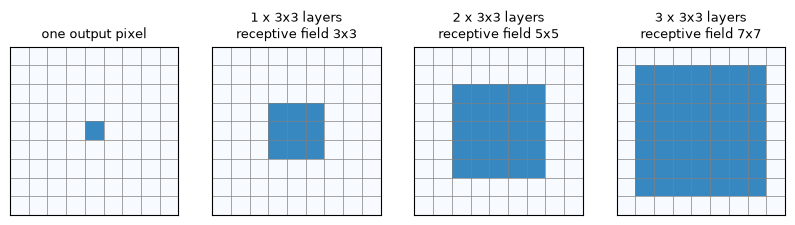

7x7 한 층: 200,704 / 3x3 세 층: 110,592


In [10]:
# 3x3을 쌓을 때 출력 한 칸이 입력의 어디까지 보는지 그립니다
fig, axes = plt.subplots(1, 4, figsize=(10, 2.8))
GRID = 9
for ax, depth in zip(axes, range(4)):
    field = np.zeros((GRID, GRID))
    half = depth   # 층이 하나 늘 때마다 수용 영역이 양쪽으로 1칸씩 넓어집니다
    field[GRID // 2 - half:GRID // 2 + half + 1, GRID // 2 - half:GRID // 2 + half + 1] = 1
    ax.imshow(field, cmap="Blues", vmin=0, vmax=1.5)
    ax.set_xticks(np.arange(-0.5, GRID), [])
    ax.set_yticks(np.arange(-0.5, GRID), [])
    ax.grid(color="gray", lw=0.5)
    ax.tick_params(length=0)
    size = 2 * half + 1
    ax.set_title(f"{depth} x 3x3 layers\nreceptive field {size}x{size}" if depth else "one output pixel", fontsize=9)
plt.show()

# 채널 수가 C로 같을 때의 파라미터 수를 실제 층으로 셉니다
C = 64
one_7x7 = nn.Conv2d(C, C, kernel_size=7, bias=False)
three_3x3 = nn.Sequential(*[nn.Conv2d(C, C, kernel_size=3, bias=False) for _ in range(3)])
print("7x7 한 층:", f"{count_params(one_7x7):,}", "/ 3x3 세 층:", f"{count_params(three_3x3):,}")

### VGG 논문의 학습 설정

입력부터 학습률까지 오늘날 표준이 된 요소가 많으니 하나씩 봅시다.

- **Mini-batch gradient descent**: 요즘 "SGD"라고 하면 보통 이것을 말합니다.
- **Momentum(0.9)**: 관성입니다. SGD는 현재 기울기만큼만 움직이는데, 모멘텀은 이전 움직임까지 고려해 더 움직입니다. 참고로 AdaGrad는 파라미터마다 다른 학습률을 주고, Adam은 RMSProp(AdaGrad의 개선판)에 모멘텀을 더한 방식입니다 (2강 3부).
- **Weight Decay(L2 norm)**: 가중치가 한없이 커지지 않게 L2 항을 손실에 더합니다. 경사 하강 식을 풀어 보면 매 스텝 가중치에 1보다 조금 작은 수를 곱하는 셈이라 "감쇠"라고 부릅니다 ([식 그림](https://t1.daumcdn.net/cfile/tistory/993E7F3C5B83528E27)).

$$W_{i+1} = W_i - \eta \nabla_W \left( L_{\text{train}} + \tfrac{1}{2}\lambda W_i^\top W_i \right) = (1 - \eta\lambda) W_i - \eta \nabla_W L_{\text{train}}$$

- **Dropout(0.5)**: 학습 때 뉴런을 확률적으로 끕니다 (4강).
- **Scheduler**: 학습률을 0.01로 시작해, 검증 정확도가 멈추면 10분의 1로 줄입니다.
- **가중치 초기화**: 논문은 먼저 얕은 모델을 학습한 뒤 그 가중치로 깊은 모델을 초기화했습니다. 논문 자신도 나중에 Xavier 초기화를 쓰면 이 사전학습 없이도 된다고 적었습니다 (2강 4부).
- **입력 이미지 크기**: 학습 입력은 224x224로 고정입니다. 다만 각 이미지를 먼저 짧은 변이 256~512 사이의 임의 크기가 되게 늘린 뒤, 그중 224x224를 잘라 씁니다. 그러면 같은 물체가 어떤 때는 얼굴만, 어떤 때는 온몸이 잡혀 여러 크기를 배웁니다. 예시 그림은 [여기](https://miro.medium.com/v2/resize:fit:1400/format:webp/1*FfnOsvhhdJQDyHg9PjrKFA.png)에 있습니다.

VGG의 끝을 합성곱으로 바꾸는 아이디어는 이후 FCN(Fully Convolutional Network for Semantic Segmentation) 논문으로 이어집니다. 7강에서 만납니다.

### VGG16 구현

VGG16은 **합성곱 13층과 완전 연결 3층**으로 이루어지고, 합성곱은 3x3만 씁니다. 합성곱 2개 묶음(앞 두 스테이지)과 3개 묶음(뒤 세 스테이지)을 함수 하나로 만들어 조립합니다. ([참고 글](https://velog.io/@euisuk-chung/%ED%8C%8C%EC%9D%B4%ED%86%A0%EC%B9%98-%ED%8C%8C%EC%9D%B4%ED%86%A0%EC%B9%98%EB%A1%9C-CNN-%EB%AA%A8%EB%8D%B8%EC%9D%84-%EA%B5%AC%ED%98%84%ED%95%B4%EB%B3%B4%EC%9E%90-VGGNet%ED%8E%B8), [torchvision 코드](https://pytorch.org/vision/main/_modules/torchvision/models/vgg.html))

In [11]:
def vgg_stage(in_channels: int, out_channels: int, num_convs: int) -> nn.Sequential:
    """3x3 합성곱을 num_convs번 쌓고 풀링으로 크기를 절반으로 줄입니다."""
    layers: list[nn.Module] = []
    for i in range(num_convs):
        layers += [nn.Conv2d(in_channels if i == 0 else out_channels, out_channels, kernel_size=3, padding=1), nn.ReLU()]
    layers.append(nn.MaxPool2d(2, 2))
    return nn.Sequential(*layers)


# VGG16의 스테이지: (기본 채널의 몇 배인가, 합성곱 수)
VGG16_STAGES = [(1, 2), (2, 2), (4, 3), (8, 3), (8, 3)]


class VGG(nn.Module):
    def __init__(self, base_dim: int, num_classes: int = 10) -> None:
        super().__init__()
        stages, in_channels = [], 3
        for multiple, num_convs in VGG16_STAGES:
            stages.append(vgg_stage(in_channels, base_dim * multiple, num_convs))
            in_channels = base_dim * multiple
        self.stages = nn.Sequential(*stages)
        # CIFAR-10은 32x32라 풀링 5번 뒤 1x1이 남습니다. ImageNet(224x224)이면 입력 크기는 512*7*7입니다.
        self.classifier = nn.Sequential(
            nn.Linear(in_channels, 4096), nn.ReLU(inplace=True), nn.Dropout(),   # inplace는 입력을 덮어쓴다는 뜻입니다
            nn.Linear(4096, 4096), nn.ReLU(inplace=True), nn.Dropout(),
            nn.Linear(4096, num_classes),
        )

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        return self.classifier(self.stages(x).flatten(start_dim=1))


vgg = VGG(base_dim=64)
print("CIFAR용 VGG16 출력:", vgg(torch.zeros(2, 3, 32, 32)).shape, "/ 파라미터:", f"{count_params(vgg):,}")
print("ImageNet용 torchvision VGG16 파라미터:", f"{count_params(models.vgg16(weights=None)):,}")

CIFAR용 VGG16 출력: torch.Size([2, 10]) / 파라미터: 33,638,218


ImageNet용 torchvision VGG16 파라미터: 138,357,544


CIFAR용은 입력이 작아 첫 완전 연결 층이 훨씬 작습니다(512 → 4096). 그래서 전체 파라미터가 약 3천4백만 개입니다. ImageNet용 VGG16의 1억 3천8백만 개는 대부분 첫 완전 연결 층(512x7x7 → 4096)에서 나옵니다. 처음 그래프에서 VGG16이 유독 오른쪽에 있는 이유입니다.

## 1.5 ResNet

**잔차 학습(residual learning)**으로 층을 수백 개까지 쌓을 수 있게 한 모델입니다. 2015년 ILSVRC 우승 모델이며, 지금도 전이학습의 출발점으로 널리 쓰입니다.

어떤 위치의 입력을 합성곱 결과에 **그대로 더해** 다음 층에 넘깁니다. 층이 배울 것이 "출력 전체" $H(x)$가 아니라 "입력과의 차이" $F(x) = H(x) - x$가 됩니다.

$$\text{out} = F(x) + x$$

- 앞에서 뽑은 특징을 변형 없이 다음 단계로 넘기므로, 앞쪽의 저수준 특징과 뒤쪽의 고수준 특징이 함께 전달됩니다.
- 더하기는 미분해도 1이 남으므로 기울기가 앞쪽 층까지 잘 흐릅니다. 아래에서 직접 확인합니다.
- 층이 배울 것이 없을 때 $F(x)=0$이면 입력이 그대로 나갑니다. 그래서 층을 더 쌓아도 얕은 모델보다 나빠지기 어렵습니다.

논문이 풀려던 문제는 **성능 저하(degradation)** 입니다. BatchNorm을 넣어 기울기가 잘 흐르는 평범한 망도 층을 더 쌓으면 **학습 오차까지** 커졌습니다. 과적합이라면 학습 오차는 오히려 작아야 하니, 깊은 망은 최적화 자체가 어렵다는 뜻입니다. 논문은 이것이 기울기 소실 때문일 가능성은 낮다고 보았고, 잔차 연결이 이 문제를 풀었습니다.

깊은 모델(50층 이상)은 계산량을 줄이려고 **bottleneck 블록**을 씁니다. 1x1 합성곱으로 채널을 줄인 뒤 3x3을 하고, 다시 1x1로 채널을 되돌립니다. 아래 그림이 두 블록을 비교합니다. 논문 그림은 [잔차 블록](https://velog.velcdn.com/images%2Feuisuk-chung%2Fpost%2F92d50f32-38d3-497f-a88b-4c2d965d38e3%2Fimage.png)과 [bottleneck](https://velog.velcdn.com/images%2Feuisuk-chung%2Fpost%2Fac17b16c-b707-48c6-a183-d020ed6539de%2Fimage.png)에서, 전체 구조는 [ResNet 논문](https://arxiv.org/abs/1512.03385)의 Table 1과 Figure 3에서 볼 수 있습니다.

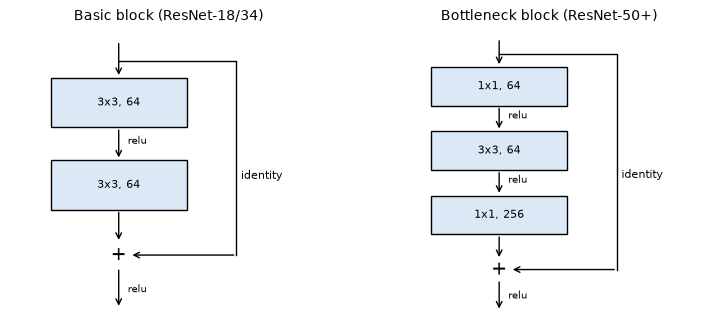

In [12]:
def draw_residual(ax: plt.Axes, title: str, layers: list[str], shortcut_label: str) -> None:
    ys = np.linspace(2.9, 2.9 - 1.0 * (len(layers) - 1), len(layers))
    for y, text in zip(ys, layers):
        draw_box(ax, 1.5, y, text)
    for upper, lower in zip(ys[:-1], ys[1:]):
        draw_arrow(ax, (1.5, upper - 0.3), (1.5, lower + 0.3))
        ax.text(1.6, (upper + lower) / 2, "relu", fontsize=7)
    plus_y = ys[-1] - 0.85
    ax.text(1.5, plus_y, "+", ha="center", va="center", fontsize=14)
    draw_arrow(ax, (1.5, ys[-1] - 0.3), (1.5, plus_y + 0.15))
    draw_arrow(ax, (1.5, plus_y - 0.15), (1.5, plus_y - 0.65))
    ax.text(1.6, plus_y - 0.45, "relu", fontsize=7)
    draw_arrow(ax, (1.5, ys[0] + 0.75), (1.5, ys[0] + 0.3))
    ax.plot([1.5, 2.8, 2.8], [ys[0] + 0.5, ys[0] + 0.5, plus_y], color="black", lw=1)
    draw_arrow(ax, (2.8, plus_y), (1.62, plus_y))
    ax.text(2.85, (ys[0] + plus_y) / 2, shortcut_label, fontsize=8)
    ax.set_xlim(0.3, 3.8)
    ax.set_ylim(plus_y - 0.8, ys[0] + 0.9)
    ax.set_title(title, fontsize=10)
    ax.axis("off")


fig, axes = plt.subplots(1, 2, figsize=(9, 3.8))
draw_residual(axes[0], "Basic block (ResNet-18/34)", ["3x3, 64", "3x3, 64"], "identity")
draw_residual(axes[1], "Bottleneck block (ResNet-50+)", ["1x1, 64", "3x3, 64", "1x1, 256"], "identity")
plt.show()

덧셈이 정말 기울기를 살리는지 실험해 봅시다. 똑같은 층을 깊게 쌓되, 한쪽만 입력을 더합니다. BatchNorm의 유무도 함께 바꿔 **맨 앞 층에 도착한 기울기의 크기**를 비교합니다. 잔차 쪽은 ResNet처럼 더한 다음 ReLU를 지납니다.

In [13]:
class ConvStack(nn.Module):
    """합성곱을 depth번 쌓습니다. residual이면 층마다 입력을 더한 뒤 ReLU를 지납니다."""

    def __init__(self, depth: int, residual: bool, batch_norm: bool, channels: int = 16) -> None:
        super().__init__()
        self.residual = residual
        self.layers = nn.ModuleList(nn.Conv2d(channels, channels, 3, padding=1) for _ in range(depth))
        self.norms = nn.ModuleList(nn.BatchNorm2d(channels) if batch_norm else nn.Identity() for _ in range(depth))

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        for layer, norm in zip(self.layers, self.norms):
            out = norm(layer(x))
            x = F.relu(x + out) if self.residual else F.relu(out)
        return x


def first_layer_grad(depth: int, residual: bool, batch_norm: bool) -> float:
    set_seed()
    stack = ConvStack(depth, residual, batch_norm)
    stack(torch.randn(8, 16, 8, 8)).mean().backward()
    return stack.layers[0].weight.grad.norm().item()


print(f"{'depth':>5s} {'plain':>10s} {'residual':>10s} {'plain+BN':>10s} {'res+BN':>10s}")
for depth in [5, 20, 50]:
    values = [first_layer_grad(depth, residual, batch_norm) for batch_norm in [False, True] for residual in [False, True]]
    print(f"{depth:5d} " + " ".join(f"{value:10.2e}" for value in values))

depth      plain   residual   plain+BN     res+BN
    5   1.86e-03   2.99e-01   1.43e-01   2.26e-01
   20   2.93e-09   2.46e+00   2.00e+00   5.08e-01
   50   7.07e-21   4.96e+01   6.01e+02   1.04e+00


BatchNorm이 없으면 입력을 더하지 않은 쪽의 기울기는 깊이에 따라 거의 0이 됩니다(기울기 소실). 더하면 사라지지 않지만 깊을수록 커집니다. BatchNorm이 있으면 평범한 망도 기울기가 사라지지 않습니다. 즉 이 표는 "잔차 연결만이 소실을 막는다"는 뜻이 아닙니다. 잔차와 BatchNorm을 함께 쓴 맨 오른쪽 칸이 가장 안정적이고, BatchNorm을 쓴 평범한 망의 성능 저하를 푼 것이 ResNet의 진짜 공헌입니다. 학습 전 초기 상태에서 시드 하나로 잰 값이니 자릿수만 보세요.

### ResNet50 구현

기본 모듈을 정의하고 bottleneck으로 조립합니다. ([참고 글](https://velog.io/@euisuk-chung/%ED%8C%8C%EC%9D%B4%ED%86%A0%EC%B9%98-%ED%8C%8C%EC%9D%B4%ED%86%A0%EC%B9%98%EB%A1%9C-CNN-%EB%AA%A8%EB%8D%B8%EC%9D%84-%EA%B5%AC%ED%98%84%ED%95%B4%EB%B3%B4%EC%9E%90-ResNet%ED%8E%B8), [torchvision 코드](https://pytorch.org/vision/main/_modules/torchvision/models/resnet.html))

잔차 블록을 구현할 때 실수하기 쉬운 곳입니다. 핵심과 직결되니 꼭 읽어 보세요.

- `if x.size() is not out.size():`처럼 쓰면 **항상 참**입니다. `is`는 값이 아니라 같은 객체인지 보는데, `.size()`는 부를 때마다 새 객체를 만들기 때문입니다. 그러면 지름길이 항상 1x1 합성곱을 지나 "그대로 더하기"가 사라집니다. 아래 코드는 크기나 채널이 달라질 때만 합성곱을 씁니다.
- 블록의 마지막 합성곱 뒤에 ReLU를 두면 $F(x)$는 음수가 될 수 없어 입력을 **더하기만** 하고 뺄 수 없습니다. 합성곱과 BatchNorm 뒤에 먼저 더한 다음 ReLU를 지나야 합니다.
- `forward`에서 전역 변수 `batch_size`를 읽으면 배치 크기가 바뀔 때 깨집니다. 평균 풀링은 어떤 입력 크기에도 동작하는 `nn.AdaptiveAvgPool2d(1)`을 씁니다.

In [14]:
def conv_bn(in_channels: int, out_channels: int, kernel_size: int, stride: int = 1) -> nn.Sequential:
    # 바로 뒤의 BatchNorm이 평균을 맞추므로 합성곱의 편향은 필요 없습니다
    return nn.Sequential(
        nn.Conv2d(in_channels, out_channels, kernel_size, stride, padding=kernel_size // 2, bias=False),
        nn.BatchNorm2d(out_channels),
    )


class Bottleneck(nn.Module):
    def __init__(self, in_channels: int, mid_channels: int, out_channels: int, stride: int = 1) -> None:
        super().__init__()
        self.residual = nn.Sequential(
            conv_bn(in_channels, mid_channels, 1), nn.ReLU(),
            conv_bn(mid_channels, mid_channels, 3, stride), nn.ReLU(),   # 크기는 3x3에서 줄입니다
            conv_bn(mid_channels, out_channels, 1),   # 활성화를 빼야 F(x)가 음수도 될 수 있습니다
        )
        # 크기나 채널이 달라질 때만 지름길에 1x1 합성곱을 둡니다. 아니면 입력을 그대로 더합니다.
        same_shape = stride == 1 and in_channels == out_channels
        self.shortcut = nn.Identity() if same_shape else conv_bn(in_channels, out_channels, 1, stride)

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        return F.relu(self.residual(x) + self.shortcut(x))


class ResNet(nn.Module):
    """50층입니다. 블록 3+4+6+3 = 16개에 블록마다 3층, 그리고 맨 앞 합성곱과 맨 뒤 완전 연결 층."""

    BLOCKS_PER_STAGE = [3, 4, 6, 3]
    EXPANSION = 4

    def __init__(self, base_dim: int, num_classes: int = 10) -> None:
        super().__init__()
        self.stem = nn.Sequential(conv_bn(3, base_dim, 7, stride=2), nn.ReLU(), nn.MaxPool2d(3, stride=2, padding=1))
        blocks: list[nn.Module] = []
        in_channels = base_dim
        for stage, num_blocks in enumerate(self.BLOCKS_PER_STAGE):
            mid_channels = base_dim * 2 ** stage
            out_channels = mid_channels * self.EXPANSION
            # 스테이지의 첫 블록이 채널을 늘리고, 첫 스테이지를 빼면 크기도 절반으로 줄입니다
            for block_index in range(num_blocks):
                stride = 2 if stage > 0 and block_index == 0 else 1
                blocks.append(Bottleneck(in_channels, mid_channels, out_channels, stride))
                in_channels = out_channels
        self.blocks = nn.Sequential(*blocks)
        self.head = nn.Sequential(nn.AdaptiveAvgPool2d(1), nn.Flatten(), nn.Linear(in_channels, num_classes))

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        return self.head(self.blocks(self.stem(x)))


resnet = ResNet(base_dim=64)
for input_size in [32, 224]:
    print(f"입력 {input_size}: 출력", resnet(torch.zeros(2, 3, input_size, input_size)).shape)
print("우리 ResNet50:", f"{count_params(resnet):,}", "/ torchvision:", f"{count_params(models.resnet50(weights=None, num_classes=10)):,}")

# is 와 == 의 차이를 확인합니다
a = torch.zeros(2, 3)
print("a.size() is a.size():", a.size() is a.size(), "/ a.size() == a.size():", a.size() == a.size())

입력 32: 출력 torch.Size([2, 10])


입력 224: 출력 torch.Size([2, 10])


우리 ResNet50: 23,528,522 / torchvision: 23,528,522


a.size() is a.size(): False / a.size() == a.size(): True


우리 구현의 파라미터 수는 `torchvision`과 같습니다. 논문처럼 스테이지의 **첫** 블록에서 크기를 줄입니다. 다만 논문은 블록의 첫 1x1 합성곱에 스트라이드를 두었는데, 여기서는 `torchvision`처럼 3x3에 둡니다. 스트라이드 2인 1x1 합성곱은 입력 픽셀의 4분의 3을 보지 않고 건너뛰기 때문입니다. 스트라이드 위치에는 파라미터가 없으니 파라미터 수만으로는 이 차이를 알 수 없습니다.

## 1.6 실습: 출력 크기와 파라미터 수 직접 계산하기

합성곱 층 하나의 출력 크기와 파라미터 수를 구하는 함수를 작성하세요.

1. `conv_output_size(w, f, p, s)`: 위의 식으로 출력 크기를 돌려줍니다.
2. `conv_params(in_ch, out_ch, f)`: 편향을 포함한 파라미터 수를 돌려줍니다. 필터 하나는 `f*f*in_ch`개의 가중치와 편향 1개를 갖고, 필터가 `out_ch`개 있습니다.

AlexNet의 첫 층(`227 → 55`, 입력 3채널, 96개 필터)으로 맞는지 확인하세요.

In [15]:
# 여기에 작성하세요

<details><summary>정답</summary>

```python
def conv_output_size(w: int, f: int, p: int, s: int) -> int:
    return (w - f + 2 * p) // s + 1


def conv_params(in_ch: int, out_ch: int, f: int) -> int:
    return (f * f * in_ch + 1) * out_ch


assert conv_output_size(227, 11, 0, 4) == 55
assert conv_output_size(55, 3, 0, 2) == 27
assert conv_output_size(224, 11, 2, 4) == 55   # torchvision의 방식
assert conv_params(3, 96, 11) == count_params(nn.Conv2d(3, 96, 11))
print(conv_output_size(227, 11, 0, 4), conv_params(3, 96, 11))
```
</details>

---
# 2부. VGG16과 ResNet50 직접 학습하기

## 2.1 CIFAR-10 불러오기

CIFAR-10은 비행기(airplane), 자동차(automobile), 새(bird), 고양이(cat), 사슴(deer), 개(dog), 개구리(frog), 말(horse), 배(ship), 트럭(truck)의 10개 클래스로 이루어진 데이터셋입니다. 이미지 크기는 3x32x32입니다. ([PyTorch 한국어 튜토리얼의 예시 그림](https://tutorials.pytorch.kr/_images/cifar10.png))

`torchvision` 데이터셋은 PIL 이미지를 돌려줍니다. `transforms.v2`의 `ToImage`와 `ToDtype`으로 이를 [0, 1] 범위의 텐서로 바꾸고(맨 앞 셀의 `TO_TENSOR`), `Normalize`가 평균 0.5와 표준편차 0.5로 [-1, 1] 범위로 옮깁니다.

In [16]:
CIFAR_MEAN = (0.5, 0.5, 0.5)
CIFAR_STD = (0.5, 0.5, 0.5)

cifar_transform = transforms.Compose([TO_TENSOR, transforms.Normalize(CIFAR_MEAN, CIFAR_STD)])

# 받은 파일은 ./data 아래에 저장됩니다
trainset = datasets.CIFAR10(root="./data", train=True, download=True, transform=cifar_transform)
testset = datasets.CIFAR10(root="./data", train=False, download=True, transform=cifar_transform)
preview_loader = DataLoader(trainset, batch_size=8, shuffle=True)   # 눈으로 보려는 용도라 작게 만듭니다

classes = ("plane", "car", "bird", "cat", "deer", "dog", "frog", "horse", "ship", "truck")
print(len(trainset), len(testset))

50000 10000


이미지를 확인해 봅시다. 그림은 저장하지 않았습니다. 실행하면 볼 수 있고, 저장된 출력에는 라벨만 남아 있습니다.

In [17]:
def imshow_cifar(img: torch.Tensor) -> None:
    """정규화를 되돌려 그립니다."""
    img = img / 2 + 0.5
    plt.figure(figsize=(8, 1.5))
    plt.imshow(np.transpose(img.numpy(), (1, 2, 0)))   # CxHxW -> HxWxC
    plt.axis("off")
    plt.show()


images, labels = next(iter(preview_loader))
imshow_cifar(utils.make_grid(images, nrow=8))
print(" ".join(f"{classes[label]:5s}" for label in labels))

truck frog  frog  ship  deer  horse car   horse


이 셀의 그림은 제3자 데이터의 사진이 보여 공개본에 저장하지 않았습니다. 실행하면 직접 볼 수 있습니다.


## 2.2 VGG16 학습하기

모델, 손실 함수, 옵티마이저를 정의합니다. 참고로 **`batch_size`를 바꾸고 나면 `DataLoader`도 다시 만들어야 합니다**. 변수만 바꿔서는 이미 만든 로더의 배치 크기가 바뀌지 않습니다.

(주의) 아래 설정 그대로 돌리면 시간이 많이 걸립니다. 학습 셀 출력의 소요 시간을 5로 나누면 에폭당 시간이고, 100에폭이면 그 100배입니다. 실행 환경에 따라 달라집니다. 빨리 돌려 보려면 `num_epoch`만 줄이세요.

> **아래 학습의 출력은 짧은 실행(5에폭) 결과입니다.** 코드의 설정은 100에폭이니, 전체 결과는 직접 실행해 확인하세요. 저장된 수치로 모델의 성능을 판단하면 안 됩니다.

In [18]:
batch_size = 100
learning_rate = 0.0002
num_epoch = 100

trainloader = DataLoader(trainset, batch_size=batch_size, shuffle=True)
testloader = DataLoader(testset, batch_size=batch_size, shuffle=False)

set_seed()
model_vgg = VGG(base_dim=64).to(device)
loss_func = nn.CrossEntropyLoss()   # criterion이라고도 부릅니다
optimizer_vgg = torch.optim.Adam(model_vgg.parameters(), lr=learning_rate)

걸린 시간은 `time.time()`으로 잽니다. 현재 시각을 초 단위로 돌려주니, 끝에서 시작을 빼면 됩니다.

In [19]:
time_start = time.time()
time.sleep(3)
time_end = time.time()
print(f"{time_end - time_start:.5f} sec")

3.00595 sec


In [20]:
start = time.time()

loss_arr = []
for epoch in range(num_epoch):
    model_vgg.train()
    running_loss = 0.0
    for image, label in trainloader:
        x = image.to(device)
        y = label.to(device)

        optimizer_vgg.zero_grad()
        output = model_vgg(x)
        loss = loss_func(output, y)
        loss.backward()
        optimizer_vgg.step()
        running_loss += loss.item()

    # 마지막 배치의 손실은 들쭉날쭉하므로 에폭 평균을 기록합니다
    loss_arr.append(running_loss / len(trainloader))
    if epoch % 10 == 0 or epoch == num_epoch - 1:
        print(f"epoch {epoch}: loss {loss_arr[-1]:.4f}")

print(f"{time.time() - start:.1f} sec")

epoch 0: loss 2.0093


epoch 4: loss 0.9372
88.5 sec


손실을 그려 봅니다.

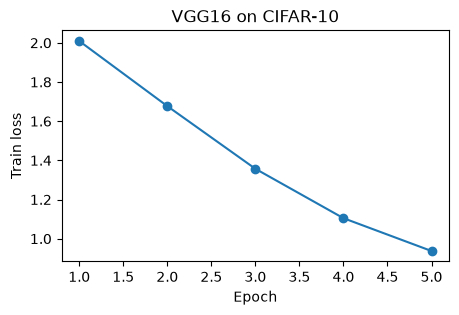

In [21]:
plt.figure(figsize=(5, 3))
plt.plot(range(1, len(loss_arr) + 1), loss_arr, marker="o")
plt.xlabel("Epoch")
plt.ylabel("Train loss")
plt.title("VGG16 on CIFAR-10")
plt.show()

## 2.3 테스트 데이터로 검사하기

평가할 때는 `model.eval()`로 Dropout과 BatchNorm을 평가 모드로 바꾸고, `torch.no_grad()`로 기울기 계산을 끕니다. 뒤에서도 쓸 수 있게 함수로 만듭니다.

In [22]:
def accuracy(model: nn.Module, loader: DataLoader) -> float:
    """loader 전체에 대한 정확도(%)를 계산합니다."""
    model.eval()
    with torch.no_grad():
        hits = sum((model(images.to(device)).argmax(dim=1).cpu() == labels).sum().item() for images, labels in loader)
    return 100 * hits / len(loader.dataset)


print(f"Accuracy of Test Data: {accuracy(model_vgg, testloader):.2f}%")

Accuracy of Test Data: 68.02%


## 2.4 실습: 클래스별 정확도

전체 정확도만 보면 어떤 클래스가 어려운지 알 수 없습니다. `model_vgg`의 클래스별 정확도를 구하세요.

- 결과는 `{클래스 이름: 정확도(%)}` 딕셔너리 `per_class`로 만듭니다.
- CIFAR-10 테스트셋은 클래스마다 1000장입니다.
- 힌트: 클래스별로 맞은 수와 전체 수를 세는 길이 10의 리스트를 둡니다.

In [23]:
# 여기에 작성하세요

<details><summary>정답</summary>

```python
hit = [0] * 10
seen = [0] * 10
model_vgg.eval()
with torch.no_grad():
    for image, label in testloader:
        pred = model_vgg(image.to(device)).argmax(dim=1).cpu()
        for p, t in zip(pred.tolist(), label.tolist()):
            seen[t] += 1
            hit[t] += int(p == t)

per_class = {name: 100 * h / s for name, h, s in zip(classes, hit, seen)}
assert seen == [1000] * 10
assert abs(sum(per_class.values()) / 10 - accuracy(model_vgg, testloader)) < 1e-6
print({name: round(value, 1) for name, value in per_class.items()})
```
</details>

## 2.5 같은 데이터셋을 ResNet50으로 학습하기

앞에서 만든 `ResNet`을 같은 방식으로 학습합니다. 코드를 보기 전에 VGG 코드를 고쳐 직접 해 보면 좋은 연습이 됩니다.

> **이 학습의 출력도 짧은 실행(5에폭) 결과입니다.** 전체 결과는 직접 실행해 확인하세요.

In [24]:
batch_size = 50
learning_rate = 0.0002
num_epoch = 100

# 배치 크기가 바뀌었으니 로더를 다시 만듭니다
trainloader = DataLoader(trainset, batch_size=batch_size, shuffle=True)
testloader = DataLoader(testset, batch_size=batch_size, shuffle=False)

set_seed()
model_resnet = ResNet(base_dim=64).to(device)
loss_func2 = nn.CrossEntropyLoss()
optimizer_resnet = torch.optim.Adam(model_resnet.parameters(), lr=learning_rate)

start = time.time()
loss_arr2 = []
for epoch in range(num_epoch):
    model_resnet.train()
    running_loss = 0.0
    for image, label in trainloader:
        x = image.to(device)
        y = label.to(device)

        optimizer_resnet.zero_grad()
        loss = loss_func2(model_resnet(x), y)
        loss.backward()
        optimizer_resnet.step()
        running_loss += loss.item()

    loss_arr2.append(running_loss / len(trainloader))
    if epoch % 10 == 0 or epoch == num_epoch - 1:
        print(f"epoch {epoch}: loss {loss_arr2[-1]:.4f}")

print(f"{time.time() - start:.1f} sec")

epoch 0: loss 1.7127


epoch 4: loss 0.8893
126.1 sec


손실을 그려 봅니다.

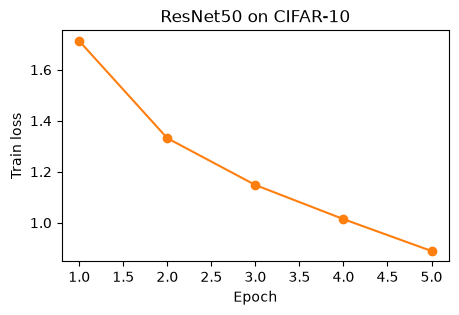

In [25]:
plt.figure(figsize=(5, 3))
plt.plot(range(1, len(loss_arr2) + 1), loss_arr2, marker="o", color="tab:orange")
plt.xlabel("Epoch")
plt.ylabel("Train loss")
plt.title("ResNet50 on CIFAR-10")
plt.show()

### 모델 성능

In [26]:
print(f"Accuracy of Test Data: {accuracy(model_resnet, testloader):.2f}%")

Accuracy of Test Data: 66.88%


**Q. 이 결과만 보고 VGG와 ResNet의 우열을 말할 수 있을까요?**

<details><summary>답</summary>

없습니다. 짧게 돌린 결과이고 배치 크기도 다릅니다. 게다가 이 ResNet은 ImageNet용 앞부분(스트라이드 2 합성곱과 풀링)을 그대로 쓰므로, 32x32 입력이 첫 단계에서 바로 8x8로 줄어듭니다. CIFAR용 ResNet은 보통 이 부분을 3x3 합성곱 하나로 바꿉니다. 이 차이가 얼마나 큰지는 숙제에서 직접 재 보세요.

</details>

---
# 3부. EfficientNet (선택)

STL10을 받고 학습하는 데 시간이 오래 걸리는 부입니다. 시간이 없으면 설명만 읽고 건너뛰어도 뒤의 부를 진행할 수 있습니다.

참고 글: [EfficientNet 논문 정리](https://greeksharifa.github.io/computer%20vision/2022/03/01/EfficientNet/), 논문: [arXiv 1905.11946](https://arxiv.org/abs/1905.11946)

**Q. 적절한 크기의 네트워크란 무엇일까요?** 모델을 키우면 정확도가 오르지만 자원도 듭니다. 논문은 먼저 지금까지의 흐름을 세 갈래로 정리합니다.

1. **ConvNet Accuracy**: AlexNet 이후 ImageNet 대회에서 더 깊고 큰 모델이 정확도를 계속 높였습니다. 최근 모델은 다른 데이터셋에서도 잘 동작합니다. 그러나 정확도가 오른 만큼 쓰는 자원도 크게 늘었습니다.
2. **ConvNet Efficiency**: 깊은 합성곱 신경망은 흔히 파라미터가 필요 이상으로 많습니다(over-parameterized). 효율을 높이려는 모델 압축 기법과 SqueezeNet, MobileNet, ShuffleNet 같은 경량 구조가 제안되었습니다.
3. **Model Scaling**: ResNet은 깊이를 달리했고(ResNet-18, 50, 200), MobileNet은 너비를 달리했습니다. 이미지 해상도를 높여도 찾아낼 정보가 많아져 정확도가 오릅니다(물론 계산량도 크게 늡니다). 그런데 이 셋의 효율적인 조합을 찾는 방법은 정립되지 않았습니다.

<details><summary>답</summary>

EfficientNet의 답은 **깊이, 너비, 해상도를 하나의 계수로 함께 키우는 것(복합 스케일링)** 입니다. 해상도가 커지면 더 넓은 범위를 봐야 하니 층이 더 필요하고, 더 세밀한 무늬를 잡으려면 채널도 더 필요합니다. 셋은 따로 놀지 않습니다.

계수 $\phi$를 하나 정하면 다음처럼 키웁니다.

$$\text{depth} = \alpha^\phi,\quad \text{width} = \beta^\phi,\quad \text{resolution} = \gamma^\phi,\quad \text{단, } \alpha \cdot \beta^2 \cdot \gamma^2 \approx 2$$

논문은 $\alpha=1.2,\ \beta=1.1,\ \gamma=1.15$를 찾았습니다. 계산량은 깊이에 비례하고 너비와 해상도의 제곱에 비례하므로, $\phi$가 1 늘 때 계산량이 약 2배가 됩니다.

</details>

아래 그림은 논문의 스케일링 그림을 단순하게 다시 그린 것입니다. 상자의 가로 길이가 채널 수, 상자의 개수가 층 수, 아래 정사각형이 입력 해상도입니다. 논문 그림은 [스케일링](https://greeksharifa.github.io/public/img/2022-03-01-EfficientNet/fig02.png)과 [크기 대비 정확도](https://greeksharifa.github.io/public/img/2022-03-01-EfficientNet/fig01.png)에 있습니다. 두 번째 그림의 핵심은 같은 정확도에서 EfficientNet이 훨씬 작다는 것으로, 1부 그래프의 빨간 점에서도 볼 수 있습니다.

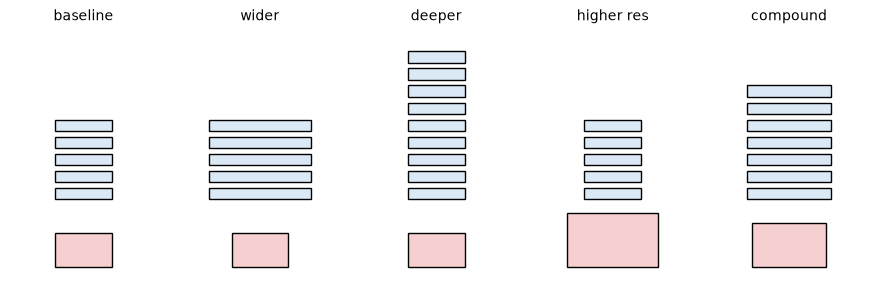

In [27]:
# 다섯 가지 스케일링의 모양만 비교합니다. 수치는 그림용입니다.
SCALINGS = [
    ("baseline", 1.0, 5, 1.0),
    ("wider", 1.8, 5, 1.0),
    ("deeper", 1.0, 9, 1.0),
    ("higher res", 1.0, 5, 1.6),
    ("compound", 1.5, 7, 1.3),
]
fig, axes = plt.subplots(1, 5, figsize=(11, 3.2))
for ax, (title, width, depth, resolution) in zip(axes, SCALINGS):
    for layer in range(depth):
        ax.add_patch(plt.Rectangle((-width / 2, 2 + layer * 0.45), width, 0.3, facecolor="#dbe9f6", edgecolor="black"))
    ax.add_patch(plt.Rectangle((-resolution / 2, 0.2), resolution, resolution * 0.9, facecolor="#f6d0d0", edgecolor="black"))
    ax.set_xlim(-1.3, 1.3)
    ax.set_ylim(0, 6.5)
    ax.set_title(title, fontsize=10)
    ax.axis("off")
plt.show()

## 3.1 데이터셋 불러오기

`torchvision`이 제공하는 STL10을 씁니다. 10개 클래스, 학습 5000장, 테스트 8000장, 원래 크기 96x96입니다. EfficientNet-B0의 기준 입력에 맞춰 224로 키웁니다. 처음 실행하면 약 2.6GB를 받으니 시간이 걸립니다. 표본 이미지 그림은 저장하지 않았습니다. 실행하면 볼 수 있습니다.

학습 5000장에서 **검증 1000장을 떼어** 설정과 가중치를 고르는 데 쓰고, 테스트 8000장은 맨 끝에 한 번만 잽니다. 테스트 세트로 고르면 테스트 점수가 낙관적이 됩니다.

In [28]:
stl_root = Path("./data")
stl_transform = transforms.Compose([TO_TENSOR, transforms.Resize(224)])

train_full = datasets.STL10(stl_root, split="train", download=True, transform=stl_transform)
test_ds = datasets.STL10(stl_root, split="test", download=True, transform=stl_transform)
train_ds, val_ds = random_split(train_full, [4000, 1000], generator=torch.Generator().manual_seed(0))
print(len(train_ds), len(val_ds), len(test_ds))

4000 1000 8000


In [29]:
EFF_BATCH_SIZE = 32
# 학습만 섞습니다. 평가는 섞을 이유가 없습니다.
train_dl, val_dl, test_dl = (DataLoader(split, batch_size=EFF_BATCH_SIZE, shuffle=split is train_ds)
                             for split in (train_ds, val_ds, test_ds))

In [30]:
def show_samples(dataset: Subset, names: list[str], count: int = 4) -> None:
    """데이터셋에서 무작위로 몇 장을 골라 라벨과 함께 그립니다."""
    fig, axes = plt.subplots(1, count, figsize=(8, 2.4))
    for ax, index in zip(axes, torch.randperm(len(dataset))[:count].tolist()):
        image, label = dataset[index]   # 이미지와 라벨을 같은 번호에서 꺼내야 짝이 맞습니다
        ax.imshow(image.permute(1, 2, 0).numpy())
        ax.set_title(names[label], fontsize=9)
        ax.axis("off")
    plt.show()


show_samples(train_ds, train_full.classes)

이 셀의 그림은 제3자 데이터의 사진이 보여 공개본에 저장하지 않았습니다. 실행하면 직접 볼 수 있습니다.


## 3.2 모델 구축하기

구성 요소는 다섯입니다. 코드는 논문의 표를 따라 새로 썼고, [zsef123의 구현](https://github.com/zsef123/EfficientNets-PyTorch/blob/master/models/effnet.py), [katsura-jp의 구현](https://github.com/katsura-jp/efficientnet-pytorch/blob/master/model/efficientnet.py), [Seonghoon-Yu의 구현](https://github.com/Seonghoon-Yu/AI_Paper_Review)을 참고했습니다.

- **Swish**: 활성화 함수 $x \cdot \sigma(x)$. PyTorch에는 `nn.SiLU`라는 이름으로 있습니다.
- **SE(Squeeze-and-Excitation) 블록**: 채널마다 "지금 얼마나 중요한가"를 0~1 값으로 계산해 곱합니다. 전역 평균 풀링으로 채널당 숫자 하나로 **짜내고(squeeze)**, 작은 신경망으로 가중치를 만들어 **흥분시킵니다(excitation)**.
- **MBConv**: 1x1로 채널을 **늘리고**, 채널별 합성곱(depthwise, 커널 3 또는 5)을 적용한 뒤 SE를 곱하고, 1x1로 다시 **줄입니다**. ResNet의 bottleneck과 반대 모양이라 inverted residual이라고 합니다. 채널별 합성곱은 `groups=채널 수`로 만듭니다. 각 채널이 자기 필터 하나만 쓰므로 파라미터가 채널 수 분의 1로 줄어듭니다. 아래 MBConv 셀의 출력에서 확인하세요.
- **SepConv**: MBConv에서 채널 확장을 하지 않는 형태입니다. 첫 스테이지에 씁니다.
- **Stochastic depth**: 학습 중 블록 전체를 확률적으로 건너뜁니다. Dropout의 블록 버전입니다. 구현해 두었지만 이번 학습에서는 켜지 않습니다. 켜려면 `efficientnet("b0", stochastic_depth=True)`처럼 만듭니다.

In [31]:
class Swish(nn.Module):
    def forward(self, x: torch.Tensor) -> torch.Tensor:
        return x * torch.sigmoid(x)


x = torch.randn(3, 3, 224, 224)
print("output size:", Swish()(x).size(), "/ nn.SiLU와 같은가:", torch.allclose(Swish()(x), nn.SiLU()(x)))

output size: torch.Size([3, 3, 224, 224]) / nn.SiLU와 같은가: True


In [32]:
class SqueezeExcite(nn.Module):
    """채널마다 0~1의 가중치를 만들어 곱합니다. 가운데를 좁혀야 병목이 됩니다."""

    def __init__(self, channels: int, bottleneck: int) -> None:
        super().__init__()
        self.gate = nn.Sequential(
            nn.AdaptiveAvgPool2d(1), nn.Flatten(),
            nn.Linear(channels, bottleneck), Swish(),
            nn.Linear(bottleneck, channels), nn.Sigmoid(),
        )

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        return x * self.gate(x)[:, :, None, None]


x = torch.randn(3, 56, 17, 17)
print("output size:", SqueezeExcite(56, 14)(x).size())

output size: torch.Size([3, 56, 17, 17])


In [33]:
# 텐서플로 코드의 momentum=0.99는 PyTorch의 0.01에 해당합니다. 두 프레임워크는 정의가 반대입니다.
# 데이터가 적은 이 실험에서는 PyTorch 기본값 0.1을 씁니다(3.3절의 비교 참고).
BN_MOMENTUM = 0.1
BN_EPS = 1e-3


def conv_bn_swish(in_channels: int, out_channels: int, kernel_size: int, stride: int = 1, groups: int = 1) -> nn.Sequential:
    return nn.Sequential(
        nn.Conv2d(in_channels, out_channels, kernel_size, stride, padding=kernel_size // 2, groups=groups, bias=False),
        nn.BatchNorm2d(out_channels, momentum=BN_MOMENTUM, eps=BN_EPS),
        Swish(),
    )


class InvertedResidual(nn.Module):
    """expand가 1보다 크면 MBConv, 1이면 SepConv입니다. survival은 학습 때 블록이 살아남을 확률입니다."""

    def __init__(self, in_channels: int, out_channels: int, kernel_size: int, stride: int, expand: int,
                 survival: float = 1.0) -> None:
        super().__init__()
        hidden = in_channels * expand
        # 크기는 채널별 합성곱에서 줄입니다. 앞쪽 1x1에서 줄이면 픽셀을 그냥 버리게 됩니다.
        widen = [conv_bn_swish(in_channels, hidden, 1)] if expand > 1 else []
        self.widen_and_filter = nn.Sequential(*widen, conv_bn_swish(hidden, hidden, kernel_size, stride, groups=hidden))
        # 논문 구현은 SE의 폭을 확장 전 채널의 1/4로 잡습니다
        self.se = SqueezeExcite(hidden, in_channels // 4)
        self.narrow = nn.Sequential(
            nn.Conv2d(hidden, out_channels, 1, bias=False),
            nn.BatchNorm2d(out_channels, momentum=BN_MOMENTUM, eps=BN_EPS),
        )
        # 크기나 채널이 바뀌는 블록은 입력을 더할 수도, 건너뛸 수도 없습니다
        self.same_shape = stride == 1 and in_channels == out_channels
        self.survival = survival if self.same_shape else 1.0

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        if self.training and self.survival < 1.0 and torch.rand(1).item() >= self.survival:
            return x   # stochastic depth: 이번 배치는 이 블록을 건너뜁니다
        out = self.narrow(self.se(self.widen_and_filter(x)))
        return x + out if self.same_shape else out


x = torch.randn(3, 16, 24, 24)
always_skip = InvertedResidual(16, 16, 3, stride=1, expand=6, survival=0.0).train()   # 살아남을 확률 0이면 입력이 그대로 나옵니다
never_skip = InvertedResidual(16, 16, 3, stride=1, expand=6).train()
print("output size:", never_skip(x).size(), "/ survival=0일 때 입력과 같은가:", torch.equal(always_skip(x), x))
plain_conv = nn.Conv2d(96, 96, 3, padding=1, bias=False)
depthwise_conv = nn.Conv2d(96, 96, 3, padding=1, bias=False, groups=96)
print("일반 합성곱:", f"{count_params(plain_conv):,}", "/ 채널별 합성곱:", f"{count_params(depthwise_conv):,}")

output size: torch.Size([3, 16, 24, 24]) / survival=0일 때 입력과 같은가: True
일반 합성곱: 82,944 / 채널별 합성곱: 864


In [34]:
# 채널을 늘리지 않는 SepConv는 expand=1입니다. 첫 스테이지에서 씁니다.
x = torch.randn(3, 16, 24, 24)
sep_conv = InvertedResidual(16, 16, 3, stride=1, expand=1).train()
print("output size:", sep_conv(x).size(), "/ 파라미터:", f"{count_params(sep_conv):,}", "/ MBConv:", f"{count_params(never_skip):,}")

output size: torch.Size([3, 16, 24, 24]) / 파라미터: 612 / MBConv: 5,220


In [35]:
# 논문 Table 1의 B0 구조: (확장 배수, 출력 채널, 반복 수, 스트라이드, 커널)
B0_STAGES = [(1, 16, 1, 1, 3), (6, 24, 2, 2, 3), (6, 40, 2, 2, 5), (6, 80, 3, 2, 3), (6, 112, 3, 1, 5), (6, 192, 4, 2, 5), (6, 320, 1, 1, 3)]
# 모델별 (너비 배수, 깊이 배수, 입력 해상도, 드롭아웃)
EFFICIENTNET_SCALES = {
    "b0": (1.0, 1.0, 224, 0.2), "b1": (1.0, 1.1, 240, 0.2), "b2": (1.1, 1.2, 260, 0.3), "b3": (1.2, 1.4, 300, 0.3),
    "b4": (1.4, 1.8, 380, 0.4), "b5": (1.6, 2.2, 456, 0.4), "b6": (1.8, 2.6, 528, 0.5), "b7": (2.0, 3.1, 600, 0.5),
}


class EfficientNet(nn.Module):
    def __init__(self, width: float, depth: float, resolution: int, dropout: float, num_classes: int = 10,
                 stochastic_depth: bool = False, min_survival: float = 0.5) -> None:
        super().__init__()
        # 내림하면 깊이 배수 1.1이 아무 효과가 없으므로 올림합니다
        plan = [(expand, int(channels * width), math.ceil(repeats * depth), stride, kernel)
                for expand, channels, repeats, stride, kernel in B0_STAGES]
        total_blocks = sum(step[2] for step in plan)

        self.resize = nn.Upsample(size=resolution, mode="bilinear", align_corners=False)
        in_channels = int(32 * width)
        self.stem = conv_bn_swish(3, in_channels, 3, stride=2)
        blocks: list[nn.Module] = []
        for expand, out_channels, repeats, stride, kernel in plan:
            for repeat in range(repeats):
                # 뒤로 갈수록 살아남을 확률을 1에서 min_survival까지 줄입니다
                survival = 1 - (1 - min_survival) * len(blocks) / (total_blocks - 1) if stochastic_depth else 1.0
                blocks.append(InvertedResidual(in_channels, out_channels, kernel, stride if repeat == 0 else 1, expand, survival))
                in_channels = out_channels
        self.blocks = nn.Sequential(*blocks)
        head_channels = int(1280 * width)
        self.head = nn.Sequential(
            conv_bn_swish(in_channels, head_channels, 1),
            nn.AdaptiveAvgPool2d(1), nn.Flatten(), nn.Dropout(dropout), nn.Linear(head_channels, num_classes),
        )

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        return self.head(self.blocks(self.stem(self.resize(x))))


def efficientnet(variant: str, num_classes: int = 10, stochastic_depth: bool = False) -> EfficientNet:
    """이름("b0"~"b7")으로 모델을 만듭니다."""
    width, depth, resolution, dropout = EFFICIENTNET_SCALES[variant]
    return EfficientNet(width, depth, resolution, dropout, num_classes, stochastic_depth)


x = torch.randn(3, 3, 224, 224)
print("output size:", efficientnet("b0")(x).size())
for variant in ["b0", "b1", "b3"]:
    tv_model = getattr(models, f"efficientnet_{variant}")(weights=None, num_classes=10)
    print(variant, f"우리 {count_params(efficientnet(variant)):,} / torchvision {count_params(tv_model):,}")
survivals = [block.survival for block in efficientnet("b0", stochastic_depth=True).blocks]
print("stochastic depth를 켠 B0의 생존 확률:", [round(s, 2) for s in survivals])

output size: torch.Size([3, 10])
b0 우리 4,020,358 / torchvision 4,020,358
b1 우리 6,525,994 / torchvision 6,525,994


b3 우리 10,553,706 / torchvision 10,711,602
stochastic depth를 켠 B0의 생존 확률: [1.0, 1.0, 0.93, 1.0, 0.87, 1.0, 0.8, 0.77, 1.0, 0.7, 0.67, 1.0, 0.6, 0.57, 0.53, 1.0]


B0와 B1의 파라미터 수는 `torchvision`과 같습니다. B3가 조금 다른 것은 `torchvision`이 채널 수를 8의 배수로 맞추기 때문입니다.

EfficientNet을 직접 구현할 때 흔한 실수를 정리합니다. 모두 실행은 되지만 동작이 틀어지는 종류입니다.

| 흔한 실수 | 문제 | 올바른 코드 |
|---|---|---|
| SE 가운데 층을 `in_channels * r`로 만듦 | 병목이 아니라 확장이 되어 B0 파라미터가 6천만 개로 불어남 | `in_channels // r`. MBConv에서는 확장 전 채널 기준으로 맞춤 |
| 텐서플로 코드의 `momentum=0.99`를 그대로 씀 | 정의가 반대라 평가용 평균이 직전 배치로 거의 덮어써짐 | PyTorch에서는 0.01 또는 기본값 0.1 (3.3절의 비교 참고) |
| 맨 앞 합성곱 뒤에 활성화를 빠뜨림 | 논문 구조와 다름 | `Swish()` 추가 |
| `int(r * depth_coef)`로 내림 | 깊이 계수 1.1이 모든 스테이지에서 효과가 없음 | `math.ceil` |
| stochastic depth 확률을 0.5에서 0으로 줄임 | 뒤쪽 블록이 거의 항상 꺼짐 | 1에서 p로 감소 |
| 스트라이드를 앞쪽 1x1 합성곱에 둠 | 크기를 줄일 때 픽셀을 그냥 버림 | 채널별 합성곱에 둠 |

구조를 표로 확인합니다. 2강에서 쓴 `torchinfo`입니다.

In [36]:
model_eff = efficientnet("b0").to(device)
print(summary(model_eff, input_size=(1, 3, 224, 224), device=device, depth=2, verbose=0))

Layer (type:depth-idx)                             Output Shape              Param #
EfficientNet                                       [1, 10]                   --
├─Upsample: 1-1                                    [1, 3, 224, 224]          --
├─Sequential: 1-2                                  [1, 32, 112, 112]         --
│    └─Conv2d: 2-1                                 [1, 32, 112, 112]         864
│    └─BatchNorm2d: 2-2                            [1, 32, 112, 112]         64
│    └─Swish: 2-3                                  [1, 32, 112, 112]         --
├─Sequential: 1-3                                  [1, 320, 7, 7]            --
│    └─InvertedResidual: 2-4                       [1, 16, 112, 112]         1,448
│    └─InvertedResidual: 2-5                       [1, 24, 56, 56]           6,004
│    └─InvertedResidual: 2-6                       [1, 24, 56, 56]           10,710
│    └─InvertedResidual: 2-7                       [1, 40, 28, 28]           15,350
│    └─InvertedResid

## 3.3 학습하기

학습 함수를 만듭니다. 손실은 합(`reduction="sum"`)으로 받아 에폭이 끝날 때 전체 개수로 나눕니다. 그러면 마지막 배치 크기가 달라도 평균이 정확합니다. 학습률을 줄일 때 가장 좋았던 가중치로 되돌리는 것도 눈여겨보세요.

학습률과 BatchNorm momentum은 아래에서 직접 비교해 정합니다.

In [37]:
loss_func_eff = nn.CrossEntropyLoss(reduction="sum")
opt_eff = optim.Adam(model_eff.parameters(), lr=0.001)   # 아래 비교로 고른 값입니다
scheduler_eff = lr_scheduler.ReduceLROnPlateau(opt_eff, mode="min", factor=0.1, patience=10)


def run_epoch(model: nn.Module, loader: DataLoader, loss_fn: nn.Module, opt: optim.Optimizer | None = None,
              one_batch: bool = False) -> tuple[float, float]:
    """한 에폭의 샘플당 손실과 정확도를 구합니다. opt가 있으면 학습합니다. one_batch면 코드 오류를 빨리 찾으려고 한 배치만 돕니다."""
    model.train(opt is not None)
    loss_sum, hits = 0.0, 0
    with torch.set_grad_enabled(opt is not None):
        for images, labels in loader:
            images, labels = images.to(device), labels.to(device)
            outputs = model(images)
            loss = loss_fn(outputs, labels)
            if opt is not None:
                opt.zero_grad()
                loss.backward()
                opt.step()
            loss_sum += loss.item()
            hits += (outputs.argmax(dim=1) == labels).sum().item()
            if one_batch:
                break
    return loss_sum / len(loader.dataset), hits / len(loader.dataset)


def train_keep_best(model: nn.Module, opt: optim.Optimizer, scheduler: lr_scheduler.ReduceLROnPlateau, epochs: int,
                    weights_path: Path, one_batch: bool = False) -> dict[str, list[float]]:
    """검증 손실이 가장 낮은 가중치를 파일과 메모리에 보관하고, 끝나면 그 가중치로 되돌립니다."""
    history: dict[str, list[float]] = {"train_loss": [], "val_loss": [], "train_acc": [], "val_acc": []}
    best_loss = float("inf")
    best_weights = copy.deepcopy(model.state_dict())
    begin = time.time()
    for epoch in range(epochs):
        lr_before = opt.param_groups[0]["lr"]
        train_loss, train_acc = run_epoch(model, train_dl, loss_func_eff, opt, one_batch)
        val_loss, val_acc = run_epoch(model, val_dl, loss_func_eff, one_batch=one_batch)
        for key, value in zip(history, [train_loss, val_loss, train_acc, val_acc]):
            history[key].append(value)
        if val_loss < best_loss:
            best_loss = val_loss
            best_weights = copy.deepcopy(model.state_dict())
            torch.save(best_weights, weights_path)
        scheduler.step(val_loss)
        if opt.param_groups[0]["lr"] != lr_before:
            print("학습률이 줄었으니 가장 좋았던 가중치로 되돌립니다")
            model.load_state_dict(best_weights)
        print(f"epoch {epoch}/{epochs - 1}, lr {lr_before}, train loss {train_loss:.4f}, val loss {val_loss:.4f}, "
              f"val acc {100 * val_acc:.2f}%, {(time.time() - begin) / 60:.1f} min")
    model.load_state_dict(best_weights)
    return history

설정을 고르려면 **검증 세트**로 짧게 비교합니다. 학습률 두 가지와 BatchNorm momentum 두 가지의 조합을 10에폭씩 돌립니다. 네 번 학습하므로 시간이 걸립니다.

In [38]:
TRIAL_EPOCHS = 10


def short_trial(bn_momentum: float, lr: float) -> tuple[float, float]:
    """주어진 설정으로 짧게 학습하고 마지막 학습 손실과 검증 정확도(%)를 돌려줍니다."""
    set_seed()
    net = efficientnet("b0").to(device)
    for module in net.modules():
        if isinstance(module, nn.BatchNorm2d):
            module.momentum = bn_momentum
    trial_opt = optim.Adam(net.parameters(), lr=lr)
    for _ in range(TRIAL_EPOCHS):
        train_loss, _ = run_epoch(net, train_dl, loss_func_eff, trial_opt)
    _, val_acc = run_epoch(net, val_dl, loss_func_eff)
    return train_loss, 100 * val_acc


print(f"{'BN momentum':>11s} {'lr':>6s} {'train loss':>10s} {'val acc(%)':>10s}")
for bn_momentum, lr in [(0.01, 0.01), (0.1, 0.01), (0.01, 0.001), (0.1, 0.001)]:
    trial_loss, trial_acc = short_trial(bn_momentum, lr)
    print(f"{bn_momentum:11.2f} {lr:6.3f} {trial_loss:10.3f} {trial_acc:10.2f}")

BN momentum     lr train loss val acc(%)


       0.01  0.010      1.525      24.90


       0.10  0.010      1.525      28.80


       0.01  0.001      0.684      29.20


       0.10  0.001      0.684      52.40


학습 손실은 momentum과 상관없이 같습니다. BatchNorm은 학습 때 배치 자체의 통계를 쓰고, momentum으로 모은 통계는 평가 때만 쓰기 때문입니다. 차이는 평가에서 납니다. 저장된 출력에서는 `momentum=0.1`, `lr=0.001`이 검증 정확도 52.4%로 가장 높아 이 값을 씁니다. momentum이 작으면 평가용 통계가 빠르게 변하는 가중치를 따라가지 못하는 것으로 보입니다. 시드 하나로 10에폭 돌린 결과이니 경향으로만 읽으세요. **학습 손실만 보면 놓치는 문제**이므로 검증 지표를 함께 봐야 합니다.

> **아래 학습의 출력은 짧은 실행(3에폭) 결과입니다.** 코드의 설정은 100에폭이니, 전체 결과는 직접 실행해 확인하세요. 저장된 수치로 모델의 성능을 판단하면 안 됩니다.

In [39]:
weights_dir = Path("./models")
weights_dir.mkdir(exist_ok=True)   # 이미 있어도 에러를 내지 않습니다
EFF_EPOCHS = 100

In [40]:
set_seed()
history_eff = train_keep_best(model_eff, opt_eff, scheduler_eff, EFF_EPOCHS, weights_dir / "weights.pt")

# 설정과 가중치를 다 고른 뒤 테스트 세트는 여기서 한 번만 잽니다
test_loss_eff, test_acc_eff = run_epoch(model_eff, test_dl, loss_func_eff)
print(f"test loss {test_loss_eff:.4f}, test acc {100 * test_acc_eff:.2f}%")

epoch 0/2, lr 0.001, train loss 1.8346, val loss 2.3215, val acc 26.00%, 0.3 min


epoch 1/2, lr 0.001, train loss 1.6062, val loss 1.6881, val acc 35.80%, 0.6 min


epoch 2/2, lr 0.001, train loss 1.4979, val loss 1.4874, val acc 42.00%, 0.9 min


test loss 1.4514, test acc 43.26%


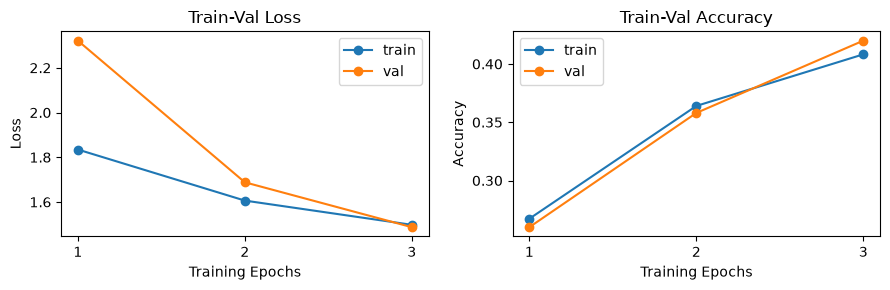

In [41]:
epochs_seen = range(1, len(history_eff["train_loss"]) + 1)
fig, axes = plt.subplots(1, 2, figsize=(9, 3))
axes[0].plot(epochs_seen, history_eff["train_loss"], marker="o", label="train")
axes[0].plot(epochs_seen, history_eff["val_loss"], marker="o", label="val")
axes[0].set_title("Train-Val Loss")
axes[0].set_ylabel("Loss")
axes[1].plot(epochs_seen, history_eff["train_acc"], marker="o", label="train")
axes[1].plot(epochs_seen, history_eff["val_acc"], marker="o", label="val")
axes[1].set_title("Train-Val Accuracy")
axes[1].set_ylabel("Accuracy")
for ax in axes:
    ax.set_xlabel("Training Epochs")
    ax.xaxis.get_major_locator().set_params(integer=True)   # 에폭은 정수로 표시합니다
    ax.legend()
plt.tight_layout()
plt.show()

## 3.4 실습: 복합 스케일링 계산하기

`compound_scale(phi)`를 작성하세요. $\alpha=1.2,\ \beta=1.1,\ \gamma=1.15$로 `(깊이 배수, 너비 배수, 해상도 배수)`를 돌려줍니다. 그리고 계산량 배수 `depth * width**2 * resolution**2`가 $\phi$에 따라 약 $2^\phi$로 늘어나는지 확인하세요.

In [42]:
# 여기에 작성하세요

<details><summary>정답</summary>

```python
ALPHA, BETA, GAMMA = 1.2, 1.1, 1.15


def compound_scale(phi: float) -> tuple[float, float, float]:
    return ALPHA ** phi, BETA ** phi, GAMMA ** phi


for phi in range(4):
    depth, width, resolution = compound_scale(phi)
    flops_ratio = depth * width ** 2 * resolution ** 2
    print(f"phi={phi}: depth x{depth:.2f}, width x{width:.2f}, resolution x{resolution:.2f} -> FLOPS x{flops_ratio:.2f}")
    assert abs(flops_ratio - 2 ** phi) / 2 ** phi < 0.3
```
</details>

---
# 4부. 모델 저장과 불러오기

혹시 Colab을 쓰다가 이런 적이 없나요?

- 런타임이 끝났으니 다시 시작하라는 메시지를 봤습니다.
- 실수로 Colab 탭을 꺼 버렸습니다.
- 잘 학습하던 코드가 버그나 다른 이유로 멈춰 버렸습니다.

학습은 네트워크 복잡도에 따라 10초 이내에서 몇 달까지 걸립니다. 쓸 때마다 새로 학습할 수는 없으니 **학습 결과를 저장해야 합니다**. 다양한 방법을 차례로 봅시다.

- pickle
- `torch.save` (관례상 확장자는 `.pt`나 `.pth`)
- TorchScript와 `torch.export`
- safetensors

시험 삼아 2강에서 만든 MNIST MLP를 학습해 씁니다.

> 원래 설정은 30에폭입니다. **아래 저장된 출력은 짧은 실행(10에폭) 결과입니다.**

In [43]:
BATCH_SIZE = 32
EPOCHS = 30

train_dataset, test_dataset = (datasets.MNIST("./data", train=is_train, download=True, transform=TO_TENSOR) for is_train in (True, False))
train_loader, test_loader = (DataLoader(split, batch_size=BATCH_SIZE, shuffle=split is train_dataset) for split in (train_dataset, test_dataset))

In [44]:
class MLP(nn.Module):
    """은닉층 두 개짜리 MNIST 분류기입니다. 층마다 BatchNorm과 Dropout을 씁니다."""

    def __init__(self) -> None:
        super().__init__()
        self.flatten = nn.Flatten()
        self.layer1 = self._hidden(28 * 28, 512)
        self.layer2 = self._hidden(512, 256)
        self.head = nn.Linear(256, 10)   # CrossEntropyLoss가 log_softmax를 포함하므로 로짓을 그대로 냅니다

    @staticmethod
    def _hidden(in_features: int, out_features: int) -> nn.Sequential:
        return nn.Sequential(nn.Linear(in_features, out_features), nn.BatchNorm1d(out_features), nn.ReLU(), nn.Dropout(0.5))

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        return self.head(self.layer2(self.layer1(self.flatten(x))))

In [45]:
def train_one_epoch(model: nn.Module, loader: DataLoader, loss_fn: nn.Module, optimizer: optim.Optimizer,
                    target_fn: Callable[[torch.Tensor], torch.Tensor] | None = None, freeze_bn: bool = False) -> float:
    """한 에폭 학습하고 샘플당 평균 손실을 돌려줍니다. target_fn으로 라벨을 바꿀 수 있습니다."""
    model.train()
    if freeze_bn:   # 5부에 설명합니다
        for module in model.modules():
            if isinstance(module, (nn.BatchNorm1d, nn.BatchNorm2d)):
                module.eval()
    total_loss = 0.0
    for image, label in loader:
        label = target_fn(label) if target_fn else label
        image, label = image.to(device), label.to(device)
        optimizer.zero_grad()
        loss = loss_fn(model(image), label)
        loss.backward()
        optimizer.step()
        total_loss += loss.item() * image.size(0)
    return total_loss / len(loader.dataset)


def evaluate(model: nn.Module, loader: DataLoader, loss_fn: nn.Module,
             target_fn: Callable[[torch.Tensor], torch.Tensor] | None = None) -> tuple[float, float]:
    """샘플당 평균 손실과 정확도(%)를 돌려줍니다."""
    model.eval()
    total_loss, correct, total = 0.0, 0, 0
    with torch.no_grad():
        for image, label in loader:
            label = target_fn(label) if target_fn else label
            image, label = image.to(device), label.to(device)
            output = model(image)
            # 배치 평균에 배치 크기를 곱해 더해야 전체 샘플 수로 나눌 수 있습니다
            total_loss += loss_fn(output, label).item() * image.size(0)
            correct += (output.argmax(dim=1) == label).sum().item()
            total += image.size(0)
    return total_loss / total, 100 * correct / total


set_seed()
model = MLP().to(device)
loss_fn = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=0.001)
# 5에폭마다 학습률을 1/10로 줄입니다. 뒤쪽 에폭은 학습률이 매우 작아 거의 움직이지 않습니다.
scheduler = optim.lr_scheduler.StepLR(optimizer, step_size=5, gamma=0.1)

TestLosses = []
LearningRates = []
for epoch in range(EPOCHS):
    train_loss = train_one_epoch(model, train_loader, loss_fn, optimizer)
    test_loss, test_acc = evaluate(model, test_loader, loss_fn)
    TestLosses.append(test_loss)
    LearningRates.append(optimizer.param_groups[0]["lr"])
    print(f"epoch {epoch}, lr {LearningRates[-1]:.0e}, train loss {train_loss:.4f}, test loss {test_loss:.4f}, test acc {test_acc:.2f}%")
    scheduler.step()

# 저장 파일이 어느 기기에서든 열리도록 CPU로 옮겨 둡니다
model = model.cpu().eval()
probe_input = torch.rand(4, 1, 28, 28)
expected_output = model(probe_input)

epoch 0, lr 1e-03, train loss 0.3271, test loss 0.1159, test acc 96.35%


epoch 1, lr 1e-03, train loss 0.2043, test loss 0.0874, test acc 97.27%


epoch 2, lr 1e-03, train loss 0.1692, test loss 0.0807, test acc 97.35%


epoch 3, lr 1e-03, train loss 0.1553, test loss 0.0715, test acc 97.62%


epoch 4, lr 1e-03, train loss 0.1370, test loss 0.0660, test acc 97.93%


epoch 5, lr 1e-04, train loss 0.1101, test loss 0.0576, test acc 98.10%


epoch 6, lr 1e-04, train loss 0.1017, test loss 0.0570, test acc 98.16%


epoch 7, lr 1e-04, train loss 0.0950, test loss 0.0543, test acc 98.29%


epoch 8, lr 1e-04, train loss 0.0866, test loss 0.0533, test acc 98.29%


epoch 9, lr 1e-04, train loss 0.0841, test loss 0.0533, test acc 98.28%


> **참고**: 2강에서 `softmax`를 넣고 `CrossEntropyLoss`를 쓰면 틀린다고 배웠습니다. 마지막에 `log_softmax`를 넣고 `CrossEntropyLoss`를 쓰는 코드도 자주 보이는데, `log_softmax`는 두 번 적용해도 값이 같아서 이 경우 **결과는 같고 중복일 뿐**입니다. 그래도 빼는 것이 맞습니다.

In [46]:
score = torch.randn(4, 10)
print("log_softmax를 두 번 적용해도 같은가:", torch.allclose(F.log_softmax(F.log_softmax(score, dim=1), dim=1), F.log_softmax(score, dim=1)))
print("softmax를 두 번 적용해도 같은가:", torch.allclose(F.softmax(F.softmax(score, dim=1), dim=1), F.softmax(score, dim=1)))

log_softmax를 두 번 적용해도 같은가: True
softmax를 두 번 적용해도 같은가: False


## 4.1 pickle

`pickle`은 파이썬의 거의 모든 객체를 저장할 수 있는 표준 라이브러리입니다. 그러니 당연히 모델도 저장할 수 있습니다.

**단점**

- 모델을 저장하려고 만든 방법이 아닙니다.
- 저장한 순서대로 불러오므로 **저장한 순서를 알아야** 합니다.
- 곧 보겠지만 **클래스 정의가 없으면 불러올 수 없습니다**.
- 파일을 여는 것만으로 **그 안의 코드가 실행될 수 있습니다**. 모르는 곳에서 받은 pickle을 열면 안 됩니다.

직접 써 봅시다.

In [47]:
my_list = ["a", "b", "c"]

# 저장: "wb"는 바이너리 쓰기입니다. with를 쓰면 끝날 때 파일이 자동으로 닫힙니다.
with open("data1.pickle", "wb") as fw:
    pickle.dump(model, fw)   # 모델 하나를 저장

with open("data2.pickle", "wb") as fw1:
    pickle.dump(model, fw1)   # 첫 번째로 모델을,
    pickle.dump(my_list, fw1)   # 두 번째로 리스트를 저장

# 불러오기: 저장한 순서 그대로 꺼냅니다
with open("data1.pickle", "rb") as fr:
    data = pickle.load(fr)
print(data)

with open("data2.pickle", "rb") as fr1:
    d1 = pickle.load(fr1)
    d2 = pickle.load(fr1)
print(type(d1).__name__, d2)

# 저장한 것보다 많이 꺼내면 EOFError가 납니다
with open("data2.pickle", "rb") as fr1:
    try:
        for count in range(3):
            pickle.load(fr1)
    except EOFError as error:
        print(f"{count + 1}번째 load에서 EOFError:", error)

# dump 도중 에러가 나면 빈 파일이 남고, 나중에 이 파일을 열 때도 같은 에러가 납니다
Path("empty.pickle").touch()
try:
    with open("empty.pickle", "rb") as fr:
        pickle.load(fr)
except EOFError as error:
    print("빈 파일에서 EOFError:", error)

MLP(
  (flatten): Flatten(start_dim=1, end_dim=-1)
  (layer1): Sequential(
    (0): Linear(in_features=784, out_features=512, bias=True)
    (1): BatchNorm1d(512, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (2): ReLU()
    (3): Dropout(p=0.5, inplace=False)
  )
  (layer2): Sequential(
    (0): Linear(in_features=512, out_features=256, bias=True)
    (1): BatchNorm1d(256, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (2): ReLU()
    (3): Dropout(p=0.5, inplace=False)
  )
  (head): Linear(in_features=256, out_features=10, bias=True)
)
MLP ['a', 'b', 'c']
3번째 load에서 EOFError: Ran out of input
빈 파일에서 EOFError: Ran out of input


### 모델 클래스를 모르는 상태에서 시험하기

런타임을 다시 시작하면 메모리가 비워져 `MLP` 클래스 정의도 사라집니다. 그 상태에서 불러오면 어떻게 될까요? 직접 해 보려면 `런타임 → 세션 다시 시작`을 고른 뒤, **새 코드 셀**에 아래를 넣어 실행하세요. 재시작하면 import도 사라지므로 이 셀 하나로 완결되어 있습니다.

```python
import pickle
with open("data1.pickle", "rb") as fr:
    model_pickle = pickle.load(fr)   # AttributeError: Can't get attribute 'MLP'
```

Run All이 끊기지 않도록 여기서는 같은 상황을 **새 파이썬 프로세스**로 만듭니다. 새 프로세스의 메모리에는 `MLP`가 없으니 런타임을 재시작한 것과 같습니다.

In [48]:
def run_fresh(code: str) -> str:
    """새 파이썬 프로세스에서 code를 실행하고 결과를 돌려줍니다. 런타임 재시작을 흉내 냅니다."""
    done = subprocess.run([sys.executable, "-W", "ignore", "-c", code], capture_output=True, text=True, timeout=300)
    if done.returncode == 0:
        return "성공: " + done.stdout.strip()
    return "실패: " + done.stderr.strip().splitlines()[-1]


LOAD_PICKLE = """
import pickle
with open("data1.pickle", "rb") as fr:
    model_pickle = pickle.load(fr)
print(type(model_pickle).__name__)
"""
print(run_fresh(LOAD_PICKLE))

실패: AttributeError: Can't get attribute 'MLP' on <module '__main__' (<class '_frozen_importlib.BuiltinImporter'>)>


`AttributeError`가 납니다. pickle 파일에는 가중치와 함께 "`__main__` 모듈의 `MLP` 클래스"라는 **이름**만 들어 있고, 코드는 들어 있지 않기 때문입니다.

### 모델을 다시 정의하면 어떨까요?

클래스 정의가 있으면 불러올 수 있습니다. 지금 이 노트북에는 위에서 정의한 `MLP`가 살아 있으니 성공합니다. 재시작한 뒤라면 맨 앞 라이브러리 셀과 `class MLP` 셀만 다시 실행하면 됩니다. 재학습은 필요 없습니다. 다만 아래 비교에 쓰는 `probe_input`과 `expected_output`은 재시작하면 사라지니, 그때는 `print(model_pickle)`로 확인하세요.

In [49]:
with open("data1.pickle", "rb") as fr:
    model_pickle = pickle.load(fr)
print(torch.allclose(model_pickle.eval()(probe_input), expected_output))

True


pickle 파일을 열기만 해도 코드가 실행되는 것을 확인해 봅시다. `__reduce__`는 "나를 복원할 때 이 함수를 불러라"라고 pickle에 알려 주는 메서드입니다. 여기서는 `print`만 부르지만, 어떤 함수든 넣을 수 있습니다.

In [50]:
class Surprise:
    def __reduce__(self) -> tuple:
        return (print, ("불러오는 것만으로 이 함수가 실행되었습니다.",))


with open("surprise.pickle", "wb") as fw:
    pickle.dump(Surprise(), fw)
with open("surprise.pickle", "rb") as fr:
    pickle.load(fr)

불러오는 것만으로 이 함수가 실행되었습니다.


## 4.2 `torch.save`

`torch.save`는 PyTorch가 제공하는 저장 함수입니다. 내부에서 pickle을 쓰고, 텐서를 효율적으로 묶어 저장합니다. 방법은 두 가지입니다.

1. **모델 객체를 통째로** 저장 (`torch.save(model, ...)`): 내부가 pickle이므로 불러올 때 **클래스 정의가 필요합니다**. 즉 "구조를 몰라도 불러올 수 있다"는 말은 틀립니다.
2. **`state_dict`만** 저장: 층 이름과 가중치 텐서의 딕셔너리입니다. 파이썬 코드를 참조하지 않습니다. 대신 모델을 먼저 만든 뒤 값을 채워 넣어야 합니다. **이 방법이 권장됩니다.**

### 방법 1: 모델 통째로

`torch.load`의 기본값은 `weights_only=True`라서 임의의 파이썬 객체를 복원하지 않습니다. 앞에서 본 pickle의 위험 때문입니다. 그래서 통째로 저장한 파일을 `torch.load("model_weights.pth")`로 열면 에러가 납니다. 믿을 수 있는 파일일 때만 `weights_only=False`를 줍니다.

In [51]:
torch.save(model, "model_weights.pth")

try:
    model_torch = torch.load("model_weights.pth")
except Exception as error:
    print(type(error).__name__, "->", str(error).splitlines()[0][:90])

model_torch = torch.load("model_weights.pth", weights_only=False)
print(torch.allclose(model_torch.eval()(probe_input), expected_output))

# 클래스 정의가 없으면 torch.save로 저장한 모델도 pickle과 똑같이 실패합니다
print(run_fresh("""
import torch
m = torch.load("model_weights.pth", weights_only=False)
print(type(m).__name__)
"""))

UnpicklingError -> Weights only load failed. This file can still be loaded, to do so you have two options, [
True


실패: AttributeError: Can't get attribute 'MLP' on <module '__main__' (<class '_frozen_importlib.BuiltinImporter'>)>


### 방법 2: `state_dict`만

`load_state_dict`는 호출한 모델에 값을 채웁니다. 새로 만든 모델이 아니라 기존 모델에 호출하면, 새 모델은 무작위 가중치 그대로 남습니다. 흔한 실수이니 아래처럼 불러올 대상에 호출하세요.

GPU에서 저장한 파일을 CPU에서 열 때는 `map_location`을 지정합니다.

In [52]:
torch.save(model.state_dict(), "model_weights_dict.pth")

model_torch2 = MLP()
print("불러오기 전 같은가:", torch.allclose(model_torch2.eval()(probe_input), expected_output))
print(model_torch2.load_state_dict(torch.load("model_weights_dict.pth", map_location="cpu")))
print("불러온 후 같은가:", torch.allclose(model_torch2.eval()(probe_input), expected_output))

# 클래스가 없어도 딕셔너리 자체는 열립니다. 무엇이 들어 있는지 볼 수 있습니다.
print(run_fresh("""
import torch
state = torch.load("model_weights_dict.pth")
print({k: list(v.shape) for k, v in list(state.items())[:3]})
"""))

불러오기 전 같은가: False
<All keys matched successfully>
불러온 후 같은가: True


성공: {'layer1.0.weight': [512, 784], 'layer1.0.bias': [512], 'layer1.1.weight': [512]}


**Q. 두 파일의 차이는 무엇일까요?** 파일 크기를 재 보고 생각해 봅시다.

In [53]:
file_size_simple = os.path.getsize("model_weights.pth")
file_size_dict = os.path.getsize("model_weights_dict.pth")
print("모델 통째로:", f"{file_size_simple:,}", "bytes")
print("state_dict:", f"{file_size_dict:,}", "bytes")
print("차이:", f"{file_size_simple - file_size_dict:,}", "bytes")

모델 통째로: 2,164,535 bytes
state_dict: 2,161,701 bytes
차이: 2,834 bytes


<details><summary>답</summary>

크기는 거의 같습니다. 가중치가 거의 전부이기 때문입니다. 차이는 1KB 남짓으로, 통째로 저장할 때 추가되는 **클래스 이름과 모듈 구조** 정보입니다.

자주 보이는 오해를 정리합니다.

- `torch.save(model)`은 옵티마이저나 에폭을 저장하지 **않습니다**. 넘긴 객체만 저장합니다. 옵티마이저까지 저장하려면 4.5절의 체크포인트처럼 직접 넣어야 합니다.
- 진짜 차이는 크기가 아니라 **코드 의존성**입니다. 통째로 저장한 파일은 클래스 이름과 그 파일 위치를 기억하므로, 코드를 옮기거나 이름을 바꾸면 열리지 않습니다. `state_dict`는 층 이름과 모양만 맞으면 열립니다. 그래서 파이썬이나 프로젝트 구조가 바뀌어도 더 튼튼합니다.

</details>

## 4.3 TorchScript와 `torch.export`

TorchScript는 모델의 **코드까지** 파일에 넣는 방식입니다. 그래서 클래스 정의가 없어도, 심지어 파이썬이 없어도(C++) 실행할 수 있습니다.

그런데 **새 코드에는 권장되지 않습니다.** PyTorch가 `torch.jit.script`에 사용 중단 경고를 냅니다. 아래 출력에서 경고 문구를 직접 확인하세요. 설치된 버전에 따라 경고가 없을 수도 있습니다. 이미 TorchScript로 배포한 모델을 읽어야 할 일은 있으니 쓰는 법은 알아 두되, 새 코드는 `torch.export`를 쓰세요. `trace`와 `script`의 차이, ONNX 변환은 10강에서 다룹니다.

In [54]:
with warnings.catch_warnings(record=True) as caught:
    warnings.simplefilter("always")
    model_scripted = torch.jit.script(model)
    model_scripted.save("model_scripted.pt")
    model_script = torch.jit.load("model_scripted.pt")

print({str(w.message) for w in caught if issubclass(w.category, (FutureWarning, DeprecationWarning))})
print(model_script)
print(torch.allclose(model_script(probe_input), expected_output))

{'`torch.jit.load` is deprecated. Please switch to `torch.export`.', '`torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.'}
RecursiveScriptModule(
  original_name=MLP
  (flatten): RecursiveScriptModule(original_name=Flatten)
  (layer1): RecursiveScriptModule(
    original_name=Sequential
    (0): RecursiveScriptModule(original_name=Linear)
    (1): RecursiveScriptModule(original_name=BatchNorm1d)
    (2): RecursiveScriptModule(original_name=ReLU)
    (3): RecursiveScriptModule(original_name=Dropout)
  )
  (layer2): RecursiveScriptModule(
    original_name=Sequential
    (0): RecursiveScriptModule(original_name=Linear)
    (1): RecursiveScriptModule(original_name=BatchNorm1d)
    (2): RecursiveScriptModule(original_name=ReLU)
    (3): RecursiveScriptModule(original_name=Dropout)
  )
  (head): RecursiveScriptModule(original_name=Linear)
)
True


### 런타임을 다시 시작한 상태에서 시험하기

pickle에서 실패했던 것과 똑같이 새 프로세스에서 불러옵니다. 이번에는 `MLP` 클래스가 없어도 됩니다.

In [55]:
print(run_fresh("""
import torch
model_script = torch.jit.load("model_scripted.pt")
print(type(model_script).__name__, model_script(torch.zeros(2, 1, 28, 28)).shape)
"""))

성공: RecursiveScriptModule torch.Size([2, 10])


같은 일을 `torch.export`로 해 봅시다. 모델을 실제로 한 번 추적해 계산 그래프로 저장합니다. 예시 입력이 필요하고, 기본으로는 **예시 입력의 배치 크기에 맞춰** 그래프가 만들어집니다.

In [56]:
exported = torch.export.export(model, (torch.zeros(2, 1, 28, 28),))
torch.export.save(exported, "model_exported.pt2")
print(run_fresh("""
import torch
loaded = torch.export.load("model_exported.pt2").module()
print(type(loaded).__name__, loaded(torch.zeros(2, 1, 28, 28)).shape)
"""))

성공: GraphModule torch.Size([2, 10])


## 4.4 safetensors

[safetensors](https://github.com/huggingface/safetensors)는 HuggingFace가 주도해 개발하는 형식입니다. **JSON 헤더와 텐서 바이너리**로만 이루어집니다.

- pickle을 쓰지 않으므로 파일을 열어도 **코드가 실행되지 않습니다**. 안전성이 가장 큰 장점입니다.
- 헤더에는 텐서의 이름, 자료형, 모양, 위치만 있습니다. **모델 구조나 코드는 들어 있지 않습니다**. 그러니 `state_dict`처럼 클래스가 필요합니다. 아래 출력의 헤더를 직접 보세요.
- 파일에서 필요한 부분만 바로 읽을 수 있어(지연 읽기) 대체로 읽기가 빠릅니다.
- 저장 용량은 `state_dict`와 거의 같습니다. 가중치 값이 같으니 당연합니다. 용량을 줄여 주는 형식은 아닙니다.

맨 앞 셀에서 설치했습니다.

In [57]:
save_model(model, "model_safetensor.safetensors")
model_safe = MLP()
load_model(model_safe, "model_safetensor.safetensors")
print(torch.allclose(model_safe.eval()(probe_input), expected_output))

# 파일 구조: 맨 앞 8바이트가 헤더 길이, 그 뒤가 JSON 헤더입니다
with open("model_safetensor.safetensors", "rb") as f:
    header_size = struct.unpack("<Q", f.read(8))[0]
    header = json.loads(f.read(header_size))
print("헤더", header_size, "bytes /", list(header.items())[:2])
print("파일 크기:", f"{os.path.getsize('model_safetensor.safetensors'):,}", "bytes")
print(run_fresh("""
from safetensors.torch import load_file
state = load_file("model_safetensor.safetensors")
print(len(state), "개 텐서")
"""))

True
헤더 1288 bytes / [('layer1.1.num_batches_tracked', {'dtype': 'I64', 'shape': [], 'data_offsets': [0, 8]}), ('layer2.1.num_batches_tracked', {'dtype': 'I64', 'shape': [], 'data_offsets': [8, 16]})]
파일 크기: 2,156,872 bytes


성공: 16 개 텐서


쓰기와 읽기 속도를 ResNet50 크기(약 100MB)로 재 봅시다. safetensors와 `mmap=True`는 파일을 메모리에 연결만 해 두고 값을 쓸 때 읽으므로, 공정하게 비교하려고 **불러온 뒤 모든 값을 한 번씩 건드립니다**. 환경에 따라 달라지니 수치는 참고만 하세요.

In [58]:
big_model = models.resnet50(weights=None)
state_big = big_model.state_dict()


def median_seconds(fn: Callable[[], object], repeat: int = 5) -> float:
    """fn을 여러 번 실행해 걸린 시간의 중앙값을 돌려줍니다."""
    times = []
    for _ in range(repeat):
        begin = time.perf_counter()
        fn()
        times.append(time.perf_counter() - begin)
    return float(np.median(times))


def touch_all(state: dict[str, torch.Tensor]) -> float:
    """지연 읽기가 실제로 일어나도록 모든 값을 더합니다."""
    return sum(value.float().sum().item() for value in state.values())


print(f"쓰기: torch.save {median_seconds(lambda: torch.save(state_big, 'big.pth')) * 1000:.1f} ms"
      f" / safetensors {median_seconds(lambda: save_model(big_model, 'big.safetensors')) * 1000:.1f} ms")
print(f"합산만 {median_seconds(lambda: touch_all(state_big)) * 1000:.1f} ms")
print(f"읽기+합산: torch.load {median_seconds(lambda: touch_all(torch.load('big.pth'))) * 1000:.1f} ms"
      f" / mmap {median_seconds(lambda: touch_all(torch.load('big.pth', mmap=True))) * 1000:.1f} ms"
      f" / safetensors {median_seconds(lambda: touch_all(load_file('big.safetensors'))) * 1000:.1f} ms")
Path("big.pth").unlink()
Path("big.safetensors").unlink()

쓰기: torch.save 107.6 ms / safetensors 49.5 ms
합산만 2.5 ms


읽기+합산: torch.load 21.2 ms / mmap 13.0 ms / safetensors 6.6 ms


| 방법 | 클래스 정의 필요 | 열 때 코드 실행 위험 | 언제 쓰나 |
|---|---|---|---|
| `pickle` | 필요 | 있음 | 모델 저장에는 쓰지 않음 |
| `torch.save(model)` | 필요 | `weights_only=False`일 때 있음 | 잠깐 쓰고 버릴 때 |
| `torch.save(state_dict)` | 필요 | 기본값에서는 없음 | **PyTorch 학습의 기본** |
| TorchScript | 불필요 | 스크립트 실행 | 기존 배포물 읽기 (신규 비권장) |
| `torch.export` | 불필요 | 그래프 실행 | 모델 정의 코드 없이 배포 |
| safetensors | 필요 | 없음 | **가중치 공유, 남의 가중치 받기** |

## 4.5 체크포인트로 학습 이어 가기

실제 학습에서는 중간중간 **이어서 학습하는 데 필요한 모든 것**을 저장합니다. 모델만이 아니라 옵티마이저와 스케줄러의 상태, 에폭까지입니다. Adam은 기울기의 이동 평균을 내부에 갖고 있어서, 옵티마이저 상태를 잃으면 이어 가도 처음과 다르게 움직입니다.

모두 `state_dict()`로 넣으면 `weights_only=True`인 기본 `torch.load`로 열 수 있습니다. `scheduler` 객체를 통째로 넣으면 기본값으로는 열리지 않습니다.

**순서도 중요합니다.** `scheduler.step()`을 부른 **뒤에** 저장해야 저장된 스케줄러 상태가 "다음 에폭"을 가리킵니다. 먼저 저장하면 재개했을 때 학습률이 한 에폭씩 밀립니다.

> 원래 설정은 30에폭입니다. **아래 저장된 출력은 짧은 실행(11에폭) 결과입니다.**

In [59]:
CHECKPOINT_EVERY = 10
epochs = 30

set_seed()
model_ckpt = MLP().to(device)
optimizer_ckpt = optim.Adam(model_ckpt.parameters(), lr=0.001)
scheduler_ckpt = optim.lr_scheduler.StepLR(optimizer_ckpt, step_size=5, gamma=0.1)

saved_paths = []
for epoch in range(epochs):
    current_lr = optimizer_ckpt.param_groups[0]["lr"]
    train_loss = train_one_epoch(model_ckpt, train_loader, loss_fn, optimizer_ckpt)
    test_loss, test_acc = evaluate(model_ckpt, test_loader, loss_fn)
    print(f"epoch {epoch}, lr {current_lr:.0e}, test loss {test_loss:.4f}, test acc {test_acc:.2f}%")
    scheduler_ckpt.step()   # 저장 전에 불러야 합니다

    if epoch % CHECKPOINT_EVERY == 0:
        path = f"model_checkpoint{epoch}.pt"
        torch.save({
            "epoch": epoch,
            "model_state_dict": model_ckpt.state_dict(),
            "optimizer_state_dict": optimizer_ckpt.state_dict(),
            "scheduler_state_dict": scheduler_ckpt.state_dict(),
            "loss": train_loss,
        }, path)
        saved_paths.append(path)
        print(f"checkpoint {path} has been saved.")

epoch 0, lr 1e-03, test loss 0.1159, test acc 96.35%
checkpoint model_checkpoint0.pt has been saved.


epoch 1, lr 1e-03, test loss 0.0874, test acc 97.27%


epoch 2, lr 1e-03, test loss 0.0807, test acc 97.35%


epoch 3, lr 1e-03, test loss 0.0715, test acc 97.62%


epoch 4, lr 1e-03, test loss 0.0660, test acc 97.93%


epoch 5, lr 1e-04, test loss 0.0576, test acc 98.10%


epoch 6, lr 1e-04, test loss 0.0570, test acc 98.16%


epoch 7, lr 1e-04, test loss 0.0543, test acc 98.29%


epoch 8, lr 1e-04, test loss 0.0533, test acc 98.29%


epoch 9, lr 1e-04, test loss 0.0533, test acc 98.28%


epoch 10, lr 1e-05, test loss 0.0521, test acc 98.34%
checkpoint model_checkpoint10.pt has been saved.


런타임이 끊겼다고 치고 마지막 체크포인트에서 이어 갑니다. 새 객체를 만들고 상태를 채운 뒤, 저장된 에폭 다음부터 돌리면 됩니다. 재개한 학습률이 끊기지 않았을 때의 값(5에폭마다 1/10)과 같은지 `assert`로 확인합니다.

In [60]:
checkpoint = torch.load(saved_paths[-1], map_location=device)

resumed_model = MLP().to(device)
resumed_optimizer = optim.Adam(resumed_model.parameters(), lr=0.001)
resumed_scheduler = optim.lr_scheduler.StepLR(resumed_optimizer, step_size=5, gamma=0.1)
resumed_model.load_state_dict(checkpoint["model_state_dict"])
resumed_optimizer.load_state_dict(checkpoint["optimizer_state_dict"])
resumed_scheduler.load_state_dict(checkpoint["scheduler_state_dict"])
start_epoch = checkpoint["epoch"] + 1

print("불러온 에폭:", checkpoint["epoch"], "/ 이어 갈 에폭:", start_epoch)
print("불러온 학습률:", resumed_optimizer.param_groups[0]["lr"], "/ 저장된 손실:", round(checkpoint["loss"], 4))
print("정확도:", round(evaluate(resumed_model, test_loader, loss_fn)[1], 2))

for epoch in range(start_epoch, start_epoch + 2):
    resumed_lr = resumed_optimizer.param_groups[0]["lr"]
    assert math.isclose(resumed_lr, 0.001 * 0.1 ** (epoch // 5), rel_tol=1e-6)
    train_one_epoch(resumed_model, train_loader, loss_fn, resumed_optimizer)
    print(f"이어서 epoch {epoch}, lr {resumed_lr:.0e}, test acc {evaluate(resumed_model, test_loader, loss_fn)[1]:.2f}%")
    resumed_scheduler.step()

불러온 에폭: 10 / 이어 갈 에폭: 11
불러온 학습률: 1e-05 / 저장된 손실: 0.0836


정확도: 98.34


이어서 epoch 11, lr 1e-05, test acc 98.33%


이어서 epoch 12, lr 1e-05, test acc 98.29%


## 4.6 실습: 체크포인트 함수 만들기

작은 모델로 저장과 복원 함수를 만듭니다.

1. `save_checkpoint(path, epoch, model, optimizer)`: 에폭, 모델 상태, 옵티마이저 상태를 저장합니다.
2. `load_checkpoint(path, model, optimizer)`: 상태를 채우고 **다음에 시작할 에폭**을 돌려줍니다.

`nn.Linear(4, 2)`를 Adam으로 한 번 갱신한 뒤 저장하고, 새 모델과 옵티마이저에 불러와 가중치와 옵티마이저 상태가 같은지 확인하세요.

In [61]:
# 여기에 작성하세요

<details><summary>정답</summary>

```python
def save_checkpoint(path: str, epoch: int, model: nn.Module, optimizer: optim.Optimizer) -> None:
    torch.save({"epoch": epoch, "model": model.state_dict(), "optimizer": optimizer.state_dict()}, path)


def load_checkpoint(path: str, model: nn.Module, optimizer: optim.Optimizer) -> int:
    saved = torch.load(path)
    model.load_state_dict(saved["model"])
    optimizer.load_state_dict(saved["optimizer"])
    return saved["epoch"] + 1


small = nn.Linear(4, 2)
small_opt = optim.Adam(small.parameters(), lr=0.01)
small(torch.rand(3, 4)).sum().backward()
small_opt.step()
save_checkpoint("small.pt", 7, small, small_opt)

restored = nn.Linear(4, 2)
restored_opt = optim.Adam(restored.parameters(), lr=0.5)
next_epoch = load_checkpoint("small.pt", restored, restored_opt)
assert next_epoch == 8
assert torch.equal(small.weight, restored.weight)
assert restored_opt.param_groups[0]["lr"] == 0.01
assert torch.equal(restored_opt.state_dict()["state"][0]["exp_avg"], small_opt.state_dict()["state"][0]["exp_avg"])
print("복원 성공, 다음 에폭:", next_epoch)
```
</details>

---
# 5부. 동결과 전이학습

인터넷을 아무리 뒤져도 우리에게 딱 맞는 모델은 없습니다.

- 사전학습된 네트워크와 데이터셋은 무수히 많지만, 우리가 원하는 것과는 미묘하게 다릅니다.
  - 예 1) 세상에 데이터셋은 많아도, 그 어떤 이미지에도 우리 집 앞마당은 찍혀 있지 않습니다.
  - 예 2) 세상에 데이터셋은 많아도, 내 웹캠으로 찍은 데이터는 없습니다.
- 어디서나 잘 되는 일반화된 모델보다, **내가 쓸 환경에 맞춘 모델**이 그 환경에서는 더 좋은 결과를 낼 수 있습니다. 그러려면 내 환경에서 얻은 데이터로 최적화해야 합니다.
- 하지만 우리는 구글도 마이크로소프트도 아니므로 데이터가 턱없이 부족합니다. YOLO 학습에 흔히 쓰는 [MS COCO](https://cocodataset.org/)만 해도 이미지가 33만 장입니다.

그래서 **많은 데이터로 학습된 모델을 조금만 고쳐 내 문제에 맞춥니다**.

## 5.1 Model freeze

원하는 만큼만 고치려면 특정 층이 학습되지 않게 고정해야 합니다. 파라미터의 `requires_grad`를 `False`로 만들면 기울기를 계산하지 않아 그 층은 변하지 않습니다.

먼저 **모든** 파라미터를 동결해 봅시다. 기울기를 계산할 대상이 하나도 없으니 `loss.backward()`가 `RuntimeError`를 냅니다. 동결이 제대로 되었다는 증거이기도 합니다.

In [62]:
frozen = copy.deepcopy(model).to(device)
for param in frozen.parameters():   # 모델의 모든 파라미터를 돌면서
    param.requires_grad = False     # 동결합니다

print("학습되는 파라미터 수:", count_trainable(frozen))
try:
    train_one_epoch(frozen, train_loader, loss_fn, optim.Adam(frozen.parameters()))
except RuntimeError as error:
    print("RuntimeError:", error)

학습되는 파라미터 수: 0
RuntimeError: element 0 of tensors does not require grad and does not have a grad_fn


**흔한 실수가 있습니다.** `requires_grad`는 **파라미터**의 속성입니다. 모듈에 대입하면(`model.head.requires_grad = True`) 에러도 나지 않고 그냥 아무 일도 일어나지 않습니다. 모듈에는 끝에 밑줄이 붙은 **메서드** `requires_grad_()`를 쓰세요.

In [63]:
demo = MLP()
print("처음:", count_trainable(demo))
demo.layer2.requires_grad = False       # 모듈에 새 속성을 하나 붙였을 뿐입니다
print("모듈에 대입한 뒤:", count_trainable(demo), "<- 그대로")
demo.layer2.requires_grad_(False)       # 모듈 안의 모든 파라미터에 적용합니다
print("requires_grad_(False) 뒤:", count_trainable(demo), "<- layer2만큼 줄어듦:", count_params(demo.layer2))

처음: 537354
모듈에 대입한 뒤: 537354 <- 그대로
requires_grad_(False) 뒤: 405514 <- layer2만큼 줄어듦: 131840


## 5.2 파인튜닝과 전이학습

- **전이학습(Transfer Learning)**: 다른 문제에서 학습한 모델을 새 문제에 가져다 쓰는 일 전체를 말합니다. 아래 둘이 대표적인 방법입니다.
- **특징 추출(Feature extraction)**: 앞부분을 동결하고 **새 출력층만** 학습합니다.
- **파인튜닝(Fine-tuning)**: 사전학습 가중치에서 시작해 **일부나 전체를 작은 학습률로 다시** 학습합니다.

구분하는 기준은 **어떤 층을 바꿨나가 아니라 어떤 층을 학습하나**입니다. 사용 예를 봅시다.

- 예 1) COCO로 학습한 탐지 모델은 승용차, 버스, 트럭 등 80종을 인식합니다. 그런데 차량 6종만 인식하고 싶습니다. → **출력층을 바꿉니다.**
- 예 2) 같은 모델로 흑백 영상(1채널)에서 차량 6종만 인식하고 싶습니다. → **입력층과 출력층을 바꿉니다.**

아래 그림의 파란 칸이 학습하는 층, 회색 칸이 동결한 층입니다.

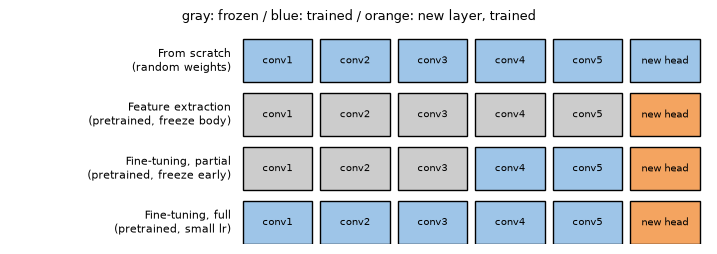

In [64]:
STRATEGIES = [
    ("From scratch\n(random weights)", ["#9ec5e8"] * 6),
    ("Feature extraction\n(pretrained, freeze body)", ["#cccccc"] * 5 + ["#f4a460"]),
    ("Fine-tuning, partial\n(pretrained, freeze early)", ["#cccccc"] * 3 + ["#9ec5e8"] * 2 + ["#f4a460"]),
    ("Fine-tuning, full\n(pretrained, small lr)", ["#9ec5e8"] * 5 + ["#f4a460"]),
]
LAYER_NAMES = ["conv1", "conv2", "conv3", "conv4", "conv5", "new head"]

fig, ax = plt.subplots(figsize=(9, 2.8))
for row, (title, colors) in enumerate(STRATEGIES):
    y = len(STRATEGIES) - 1 - row
    ax.text(-0.15, y + 0.4, title, ha="right", va="center", fontsize=8)
    for col, color in enumerate(colors):
        ax.add_patch(plt.Rectangle((col, y), 0.9, 0.8, facecolor=color, edgecolor="black"))
        ax.text(col + 0.45, y + 0.4, LAYER_NAMES[col], ha="center", va="center", fontsize=7)
ax.set_xlim(-3, 6)
ax.set_ylim(0, len(STRATEGIES))
ax.set_title("gray: frozen / blue: trained / orange: new layer, trained", fontsize=9)
ax.axis("off")
plt.show()

## 5.3 숫자 인식 모델을 홀짝 인식 모델로 바꾸기

학습된 숫자 분류기의 출력층을 2개짜리로 바꾸고 그 층만 학습합니다. 라벨을 2로 나눈 나머지로 바꾸면 0은 짝수, 1은 홀수가 됩니다.

전이학습에서 자주 틀리는 부분이 세 가지 있습니다.

1. **순서**: 출력층을 바꾼 **뒤에** 전체를 동결하면 새 출력층까지 얼어 `RuntimeError`가 납니다. 동결한 **다음에** 출력층을 바꾸면 새 층은 기본값이 `requires_grad=True`입니다.
2. **옵티마이저**: 옵티마이저는 만들 때 넘긴 파라미터만 갱신합니다. 새 층을 넣으려면 옵티마이저를 **새로 만들어야** 합니다.
3. **무엇을 전이하나**: 학습된 모델에서 시작해야 전이입니다. 새로 만든 `MLP()`를 얼리면 무작위 값을 얼리는 셈입니다.

또 하나, BatchNorm의 평균과 분산은 `requires_grad`와 상관없이 `model.train()` 상태면 계속 갱신됩니다. 정말로 고정하려면 BatchNorm 층을 `eval()`로 두어야 합니다. `train_one_epoch`의 `freeze_bn`이 그 일을 합니다.

학습된 몸통이 얼마나 도움이 되는지 보려고, **무작위 몸통**을 동결한 대조군과 비교합니다.

> 원래 설정은 20에폭입니다. **아래 저장된 출력은 짧은 실행(5에폭) 결과입니다.**

In [65]:
def parity(label: torch.Tensor) -> torch.Tensor:
    """0은 짝수, 1은 홀수입니다."""
    return label % 2


def make_parity_model(body: MLP) -> MLP:
    """몸통을 동결한 뒤 출력층을 2개짜리로 바꿉니다. 순서가 중요합니다."""
    parity_model = copy.deepcopy(body)
    for param in parity_model.parameters():
        param.requires_grad = False
    parity_model.head = nn.Linear(256, 2)   # 새로 만든 층은 requires_grad=True입니다
    return parity_model.to(device)


epochs = 20
set_seed()
results = {}
for name, body in [("trained body", model), ("random body", MLP())]:
    parity_model = make_parity_model(body)
    # 옵티마이저에 새 층만 넘깁니다
    parity_opt = optim.Adam(parity_model.head.parameters(), lr=0.001)
    bn_before = parity_model.layer1[1].running_mean.clone()
    layer_before = parity_model.layer1[0].weight.clone()
    for epoch in range(epochs):
        train_one_epoch(parity_model, train_loader, loss_fn, parity_opt, target_fn=parity, freeze_bn=True)
    results[name] = evaluate(parity_model, test_loader, loss_fn, target_fn=parity)[1]
    assert torch.equal(layer_before, parity_model.layer1[0].weight)                   # 동결된 층이 그대로인지 확인합니다
    assert torch.equal(bn_before, parity_model.layer1[1].running_mean)      # BatchNorm 통계도 그대로인지 확인합니다
    print(f"{name}: 학습되는 파라미터 {count_trainable(parity_model)}개, 홀짝 정확도 {results[name]:.2f}%")

trained body: 학습되는 파라미터 514개, 홀짝 정확도 98.41%


random body: 학습되는 파라미터 514개, 홀짝 정확도 79.22%


새 층의 파라미터 514개만 학습했는데, 저장된 짧은 실행(시드 하나)에서 학습된 몸통은 98.41%, 무작위 몸통은 79.22%입니다. 이 실행에서는 몸통이 무엇을 배웠느냐에 따라 차이가 크게 났습니다. 무작위 몸통이 찍는 수준(50%)보다 높은 것은 무작위 변환을 거쳐도 입력의 정보가 어느 정도 남기 때문으로 보입니다. 원래 설정으로 돌려 확인해 보세요.

## 5.4 입력과 출력을 함께 바꾸기: ResNet18로 MNIST 분류

이번에는 ImageNet으로 학습된 ResNet18을 MNIST에 맞춥니다. 입력이 RGB 3채널에서 흑백 1채널로, 출력이 1000개에서 10개로 바뀌니 **첫 층과 마지막 층을 교체**합니다. 나머지는 동결합니다.

- 가중치는 `weights=`로 고릅니다.
- `resnet_pt.conv1.requires_grad = True` 같은 줄은 앞서 본 대로 효과가 없으니 쓰지 않습니다. 새 층은 원래 학습됩니다.
- BatchNorm은 `freeze_bn=False`로 둡니다. MNIST는 ImageNet과 통계가 많이 다르고 첫 층도 새것이라, 통계는 새 데이터에 맞게 갱신되도록 둡니다.

**검증 세트**를 따로 떼어 냅니다. 테스트 정확도가 가장 높은 가중치를 고르면 테스트 세트로 모델을 고른 셈이라 마지막 테스트 점수가 낙관적이 됩니다. 학습 함수도 하나로 합칩니다.

학습률은 `CosineAnnealingLR`로 코사인 곡선을 따라 `T_max` 에폭에 걸쳐 0에 가깝게 줄입니다. `T_max`는 실제 에폭 수에 맞춥니다.

In [66]:
def fit(model: nn.Module, train_dl_: DataLoader, val_dl_: DataLoader, criterion: nn.Module, optimizer: optim.Optimizer,
        scheduler: lr_scheduler.LRScheduler, epoch_length: int, print_every: int = 5) -> dict[str, list[float]]:
    """검증 정확도가 가장 높았던 가중치를 복원해 끝냅니다."""
    history: dict[str, list[float]] = {"train_loss": [], "val_loss": [], "val_acc": []}
    best_acc = -1.0
    best_model_wts = copy.deepcopy(model.state_dict())
    start_time = time.time()
    for epoch in range(epoch_length):
        train_loss = train_one_epoch(model, train_dl_, criterion, optimizer)
        val_loss, val_acc = evaluate(model, val_dl_, criterion)
        scheduler.step()
        history["train_loss"].append(train_loss)
        history["val_loss"].append(val_loss)
        history["val_acc"].append(val_acc)
        if val_acc > best_acc:
            best_acc = val_acc
            best_model_wts = copy.deepcopy(model.state_dict())
        if print_every and (epoch % print_every == 0 or epoch == epoch_length - 1):
            print(f"Epoch {epoch} | train loss {train_loss:.4f} | val loss {val_loss:.4f} | val acc {val_acc:.2f}%")
    # 복원은 반복문이 끝난 뒤에 한 번만 합니다. 안에서 하면 매 에폭 학습 결과를 되돌리게 됩니다.
    model.load_state_dict(best_model_wts)
    if print_every:
        learning_time = time.time() - start_time
        print(f"Best val acc {best_acc:.2f}% | Learning time: {learning_time // 60:.0f}m {learning_time % 60:.0f}s")
    return history


set_seed()
mnist_train, mnist_val = random_split(train_dataset, [55000, 5000], generator=torch.Generator().manual_seed(0))
mnist_train_loader = DataLoader(mnist_train, batch_size=BATCH_SIZE, shuffle=True)
mnist_val_loader = DataLoader(mnist_val, batch_size=256)
mnist_test_loader = DataLoader(test_dataset, batch_size=256)

resnet_pt = models.resnet18(weights=models.ResNet18_Weights.IMAGENET1K_V1)
for param in resnet_pt.parameters():   # 일단 전부 동결합니다
    param.requires_grad = False

# 입력층과 출력층을 교체합니다. 새 층은 학습 대상입니다.
resnet_pt.conv1 = nn.Conv2d(1, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False)
resnet_pt.fc = nn.Linear(resnet_pt.fc.in_features, 10)
resnet_pt = resnet_pt.to(device)
print("학습되는 파라미터:", f"{count_trainable(resnet_pt):,}", "/ 전체:", f"{count_params(resnet_pt):,}")

criterion = nn.CrossEntropyLoss()
optimizer_pt = optim.SGD([p for p in resnet_pt.parameters() if p.requires_grad], lr=0.001, momentum=0.9)
epoch_length = 20
# T_max를 에폭 수보다 훨씬 크게 잡으면 학습률이 거의 줄지 않습니다
scheduler_pt = lr_scheduler.CosineAnnealingLR(optimizer_pt, T_max=epoch_length)

history_pt = fit(resnet_pt, mnist_train_loader, mnist_val_loader, criterion, optimizer_pt, scheduler_pt, epoch_length)
print(f"Test acc: {evaluate(resnet_pt, mnist_test_loader, criterion)[1]:.2f}%")

학습되는 파라미터: 8,266 / 전체: 11,175,370


Epoch 0 | train loss 0.8411 | val loss 0.4962 | val acc 84.90%


Epoch 5 | train loss 0.3805 | val loss 0.3131 | val acc 90.78%


Epoch 10 | train loss 0.3298 | val loss 0.2744 | val acc 91.92%


Epoch 15 | train loss 0.3041 | val loss 0.2474 | val acc 92.78%


Epoch 19 | train loss 0.2954 | val loss 0.2455 | val acc 92.58%
Best val acc 92.78% | Learning time: 3m 44s


Test acc: 92.43%


## 5.5 실습: 입력층을 사전학습 가중치로 초기화하기

위에서는 첫 층을 무작위로 새로 만들었습니다. 학습된 RGB 필터를 버리는 셈입니다. **세 채널의 가중치를 평균**하면 1채널 필터로 재활용할 수 있습니다.

`adapt_conv1(pretrained_conv)`를 작성하세요. ResNet의 첫 층처럼 편향이 없는 3채널 `nn.Conv2d`를 받아, 커널, 스트라이드, 패딩이 같은 1채널 층을 만들고 가중치를 채널 방향 평균으로 채워 돌려줍니다.

In [67]:
# 여기에 작성하세요

<details><summary>정답</summary>

```python
def adapt_conv1(pretrained_conv: nn.Conv2d) -> nn.Conv2d:
    new_conv = nn.Conv2d(1, pretrained_conv.out_channels, kernel_size=pretrained_conv.kernel_size,
                         stride=pretrained_conv.stride, padding=pretrained_conv.padding, bias=False)
    with torch.no_grad():
        new_conv.weight.copy_(pretrained_conv.weight.mean(dim=1, keepdim=True))
    return new_conv


source_conv = nn.Conv2d(3, 64, kernel_size=7, stride=2, padding=3, bias=False)
adapted = adapt_conv1(source_conv)
assert adapted.weight.shape == (64, 1, 7, 7)
assert torch.allclose(adapted.weight[0, 0], source_conv.weight[0].mean(dim=0))
assert adapted(torch.zeros(1, 1, 28, 28)).shape == source_conv(torch.zeros(1, 3, 28, 28)).shape
print(adapted)
```
</details>

## 5.6 동결을 조금 덜 하고 싶다면

앞을 아예 얼리지 말고, 절반만 얼리거나 아주 작은 학습률만 주고 싶을 수 있습니다. 옵티마이저에 **파라미터 묶음(param group)** 을 넘기면 묶음마다 다른 학습률을 줄 수 있습니다. 아무것도 적지 않은 묶음은 기본 `lr`을 씁니다.

```python
optim.SGD([{"params": model.base.parameters()},
           {"params": model.classifier.parameters(), "lr": 1e-3}
           ], lr=1e-4, momentum=0.9)
```

사전학습된 앞쪽은 이미 쓸 만하니 **작은 학습률**로, 새로 만든 뒤쪽은 **큰 학습률**로 두는 것이 보통입니다. 다만 모델에서 앞과 뒤를 미리 구분해 둬야 합니다. ResNet18은 `conv1`, `layer1~4`, `fc`로 나뉘어 있습니다.

In [68]:
partial = models.resnet18(weights=None)
partial.fc = nn.Linear(partial.fc.in_features, 2)

# 앞쪽 층은 동결하고 layer4와 fc만 학습합니다
for param in partial.parameters():
    param.requires_grad = False
for param in partial.layer4.parameters():
    param.requires_grad = True
for param in partial.fc.parameters():
    param.requires_grad = True

partial_opt = optim.SGD([
    {"params": partial.layer4.parameters()},        # 기본 학습률
    {"params": partial.fc.parameters(), "lr": 1e-3},
], lr=1e-4, momentum=0.9)

print("학습되는 파라미터:", f"{count_trainable(partial):,}", "/ 전체:", f"{count_params(partial):,}")
for group in partial_opt.param_groups:
    print("lr", group["lr"], "/ 파라미터 묶음 크기", sum(p.numel() for p in group["params"]))

학습되는 파라미터: 8,394,754 / 전체: 11,177,538
lr 0.0001 / 파라미터 묶음 크기 8393728
lr 0.001 / 파라미터 묶음 크기 1026


## 5.7 비슷하지만 다른 데이터에 맞추기: SEMEION

MNIST로 학습한 모델을 다른 손글씨 데이터에 맞춰 봅시다. 범용성을 조금 포기하고 **내 데이터에 맞추는** 일입니다. 과적합과 비슷해 보이지만 과적합은 나쁜 뜻으로 쓰는 말이니, 여기서는 **도메인 적응**이라고 부르겠습니다.

이 절의 "MNIST 모델"은 5.4절의 `resnet_pt`입니다. 몸통은 ImageNet 가중치이고, MNIST로 학습한 것은 첫 층과 마지막 층(파라미터 8,266개)과 BatchNorm 통계입니다.

[SEMEION](https://archive.ics.uci.edu/dataset/178/semeion+handwritten+digit)은 MNIST와 마찬가지로 손글씨 숫자이지만 차이가 있습니다.

1. MNIST는 0~1 사이의 실수값이고, SEMEION은 0 또는 1의 이진값입니다.
2. 해상도가 다릅니다. MNIST는 28x28, SEMEION은 16x16입니다.
3. 양이 훨씬 적습니다. SEMEION은 1593장입니다.

MNIST (1, 28, 28) 고유값 수 78
SEMEION (1, 16, 16) 고유값 수 2 / 전체 1593 장
평균 밝기(획이 차지하는 정도): MNIST 0.128 / SEMEION 0.325


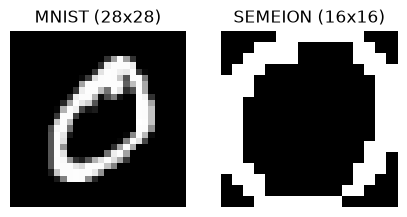

In [69]:
# 내려받을 때 진행 표시가 길게 나오므로 출력을 숨깁니다
with contextlib.redirect_stdout(io.StringIO()):
    ds_semeion = datasets.SEMEION(root="./data", download=True, transform=TO_TENSOR)

mnist_sample, _ = train_dataset[1]
semeion_sample, _ = ds_semeion[1]
print("MNIST", tuple(mnist_sample.shape), "고유값 수", mnist_sample.unique().numel())
print("SEMEION", tuple(semeion_sample.shape), "고유값 수", semeion_sample.unique().numel(), "/ 전체", len(ds_semeion), "장")
mnist_ink = torch.stack([train_dataset[i][0].mean() for i in range(1000)]).mean().item()
semeion_ink = torch.stack([ds_semeion[i][0].mean() for i in range(1000)]).mean().item()
print(f"평균 밝기(획이 차지하는 정도): MNIST {mnist_ink:.3f} / SEMEION {semeion_ink:.3f}")

fig, axes = plt.subplots(1, 2, figsize=(5, 2.5))
axes[0].imshow(mnist_sample.squeeze().numpy(), cmap="gray")
axes[0].set_title("MNIST (28x28)")
axes[1].imshow(semeion_sample.squeeze().numpy(), cmap="gray")
axes[1].set_title("SEMEION (16x16)")
for ax in axes:
    ax.axis("off")
plt.show()

학습, 검증, 테스트로 나눕니다. MNIST로 학습한 모델을 그대로 쓰면 얼마나 맞힐까요? 해상도 차이가 문제인지도 보려고, MNIST 크기로 키운 경우와 함께 재 봅시다.

In [70]:
semeion_28 = datasets.SEMEION(root="./data", transform=transforms.Compose([transforms.Resize(28), TO_TENSOR]))
n_total = len(ds_semeion)
n_val = n_test = n_total // 10
indices = torch.randperm(n_total, generator=torch.Generator().manual_seed(0)).tolist()
train_idx, val_idx, test_idx = indices[n_val + n_test:], indices[:n_val], indices[n_val:n_val + n_test]
print("학습", len(train_idx), "/ 검증", len(val_idx), "/ 테스트", len(test_idx))

train_loader2 = DataLoader(Subset(semeion_28, train_idx), batch_size=BATCH_SIZE, shuffle=True)
val_loader2 = DataLoader(Subset(semeion_28, val_idx), batch_size=256)
test_loader2 = DataLoader(Subset(semeion_28, test_idx), batch_size=256)

test_16 = DataLoader(Subset(ds_semeion, test_idx), batch_size=256)
print(f"MNIST 모델 그대로, 16x16 입력: {evaluate(resnet_pt, test_16, criterion)[1]:.2f}%")
print(f"MNIST 모델 그대로, 28x28로 키운 입력: {evaluate(resnet_pt, test_loader2, criterion)[1]:.2f}%")

학습 1275 / 검증 159 / 테스트 159
MNIST 모델 그대로, 16x16 입력: 12.58%


MNIST 모델 그대로, 28x28로 키운 입력: 24.53%


같은 손글씨인데 인식률이 매우 낮습니다. 위 결과처럼 크기를 맞추면 나아지지만, 여전히 네 장 중 한 장꼴로 맞힐 뿐입니다. 위 그림과 평균 밝기를 보면 SEMEION은 획이 훨씬 굵고 숫자가 칸을 가득 채웁니다. 사람 눈에는 같은 숫자여도 모델에게는 다른 데이터입니다.

**내 데이터로 다시 학습해 봅시다.** 동결을 모두 풀고 MNIST 모델에서 시작합니다. 비교를 위해 **사전학습 없이 무작위로 시작한** 같은 모델도 학습합니다.

두 가지를 주의합니다.

- 입력(1채널)과 출력(숫자 10개)이 MNIST와 같으니 `conv1`과 `fc`를 새 층으로 바꿀 필요가 없습니다. 바꾸면 학습된 입출력층을 버리게 됩니다.
- `load_state_dict(best_model_wts)`를 반복문 안에 두면 **매 에폭 학습 결과를 되돌립니다**. `fit`은 끝난 뒤에 한 번만 복원합니다.

테스트 세트가 작으니(159장, 한 장이 약 0.6%포인트) 시드를 바꿔 3번씩 돌려 평균을 봅니다. 데이터 분할은 고정이고, 시드는 초기화와 섞는 순서만 바꿉니다.

MNIST pretrained: 테스트 97.06% (시드별 [96.23, 98.74, 96.23])


from scratch: 테스트 95.60% (시드별 [94.97, 94.34, 97.48])
3.8 min


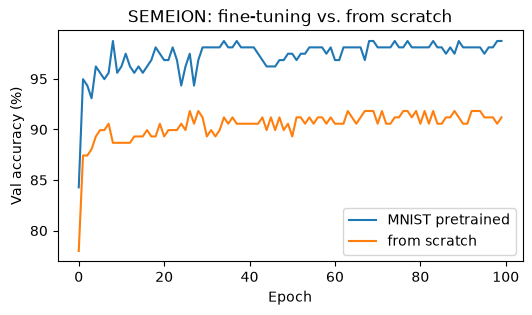

In [71]:
def make_scratch_resnet() -> nn.Module:
    """사전학습 없는 같은 구조를 만듭니다."""
    scratch = models.resnet18(weights=None)
    scratch.conv1 = nn.Conv2d(1, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False)
    scratch.fc = nn.Linear(scratch.fc.in_features, 10)
    return scratch


def make_finetune_resnet() -> nn.Module:
    """MNIST 모델을 복사하고 동결을 모두 풉니다."""
    tuned = copy.deepcopy(resnet_pt)
    for param in tuned.parameters():
        param.requires_grad = True
    return tuned


SEEDS = [0, 1, 2]
epoch_length = 100
semeion_results: dict[str, list[float]] = {}
semeion_curves: dict[str, list[float]] = {}
start_time = time.time()
for name, builder in [("MNIST pretrained", make_finetune_resnet), ("from scratch", make_scratch_resnet)]:
    semeion_results[name] = []
    for seed in SEEDS:
        set_seed(seed)
        net = builder().to(device)
        opt2 = optim.SGD(net.parameters(), lr=0.001, momentum=0.9)
        sch2 = lr_scheduler.CosineAnnealingLR(opt2, T_max=epoch_length)
        hist = fit(net, train_loader2, val_loader2, criterion, opt2, sch2, epoch_length, print_every=0)
        semeion_results[name].append(evaluate(net, test_loader2, criterion)[1])
    semeion_curves[name] = hist["val_acc"]   # 마지막 시드의 곡선만 그립니다
    scores = semeion_results[name]
    print(f"{name}: 테스트 {np.mean(scores):.2f}% (시드별 {[round(s, 2) for s in scores]})")
print(f"{(time.time() - start_time) / 60:.1f} min")

plt.figure(figsize=(6, 3))
for name, curve in semeion_curves.items():
    plt.plot(curve, label=name)
plt.xlabel("Epoch")
plt.ylabel("Val accuracy (%)")
plt.title("SEMEION: fine-tuning vs. from scratch")
plt.legend()
plt.show()

결과를 정직하게 읽어 봅시다. 평균은 MNIST 사전학습이 97.06%, 무작위 시작이 95.60%로 1.46%포인트 차이입니다. 그런데 시드별 값이 94.34~98.74% 사이에서 서로 겹치고, 테스트 한 장이 약 0.6%포인트입니다. **이 데이터 양으로는 최종 정확도에서 사전학습의 이득이 있다고 말하기 어렵습니다.** 그래프를 보면 마지막 시드에서는 사전학습 쪽이 첫 에폭부터 앞서고 검증 정확도도 높은데, 테스트에서는 그 시드의 순서가 뒤집혔습니다(96.23% 대 97.48%). 숙제 5에서 학습 데이터를 줄이면 어떻게 되는지 확인해 보세요.

재학습 없이 MNIST 모델을 그대로 쓸 때의 24.53%와 비교하면, 내 데이터로 다시 학습하는 일 자체의 효과는 분명합니다.

---
# 6부. 파인튜닝 실습: 개미와 벌

PyTorch 공식 [전이학습 튜토리얼](https://pytorch.org/tutorials/beginner/transfer_learning_tutorial.html)(BSD 라이선스, Sasank Chilamkurthy 작성, [한국어판 Colab](https://colab.research.google.com/github/PyTorchKorea/tutorials-kr/blob/master/docs/_downloads/74249e7f9f1f398f57ccd094a4f3021b/transfer_learning_tutorial.ipynb))을 다듬은 실습입니다. 두 방법을 비교합니다.

- **합성곱 신경망의 파인튜닝**: 무작위 초기화 대신 ImageNet 등으로 미리 학습한 신경망으로 초기화합니다. 학습의 나머지 과정은 평소와 같습니다.
- **고정된 특징 추출기로서의 합성곱 신경망**: 마지막 완전 연결 층을 제외한 모든 가중치를 고정합니다. 마지막 층은 새 무작위 가중치를 가진 층으로 바꾸고 이 층만 학습합니다.

## 6.1 데이터 불러오기

**개미**와 **벌**을 분류하는 모델을 학습합니다. 학습 이미지가 클래스별 약 120장, 검증 이미지가 클래스별 약 75장입니다. 맨 처음부터 학습한다면 일반화하기에 아주 작은 데이터셋이지만, 전이학습을 쓰면 꽤 잘 일반화할 수 있습니다. ImageNet의 아주 작은 일부를 가져온 데이터입니다.

In [72]:
HYMENOPTERA_URL = "https://download.pytorch.org/tutorial/hymenoptera_data.zip"
DOWNLOAD_TIMEOUT_SEC = 120


def download_hymenoptera(root: Path) -> Path:
    """압축 파일을 받아 풉니다. 이미 있으면 건너뜁니다."""
    target = root / "hymenoptera_data"
    if target.exists():
        return target
    root.mkdir(exist_ok=True)
    zip_path = root / "hymenoptera_data.zip"
    with urllib.request.urlopen(HYMENOPTERA_URL, timeout=DOWNLOAD_TIMEOUT_SEC) as response:
        zip_path.write_bytes(response.read())
    with zipfile.ZipFile(zip_path) as archive:
        archive.extractall(root)
    return target


data_dir = download_hymenoptera(Path("./data"))
print(sorted(path.name for path in data_dir.iterdir()))

['train', 'val']


In [73]:
# 학습에는 증강(augmentation)과 정규화를, 검증에는 정규화만 적용합니다
IMAGENET_MEAN = [0.485, 0.456, 0.406]
IMAGENET_STD = [0.229, 0.224, 0.225]
data_transforms = {
    "train": transforms.Compose([
        transforms.RandomResizedCrop(224),
        transforms.RandomHorizontalFlip(),
        TO_TENSOR,
        transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD),
    ]),
    "val": transforms.Compose([
        transforms.Resize(256),
        transforms.CenterCrop(224),
        TO_TENSOR,
        transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD),
    ]),
}

image_datasets = {x: datasets.ImageFolder(data_dir / x, data_transforms[x]) for x in ["train", "val"]}
dataloaders = {x: DataLoader(image_datasets[x], batch_size=4, shuffle=(x == "train"), num_workers=2, persistent_workers=True)
               for x in ["train", "val"]}
dataset_sizes = {x: len(image_datasets[x]) for x in ["train", "val"]}
class_names = image_datasets["train"].classes
print(dataset_sizes, class_names)
for x in ["train", "val"]:
    print(x, "클래스별 장수:", np.bincount(image_datasets[x].targets).tolist())

{'train': 244, 'val': 153} ['ants', 'bees']
train 클래스별 장수: [123, 121]
val 클래스별 장수: [70, 83]


### 일부 이미지 시각화하기

증강이 어떻게 적용되는지 학습 이미지를 몇 장 봅시다. 이 이미지들은 재게시 조건이 불확실해 그림을 저장하지 않았습니다. 실행하면 볼 수 있습니다.

In [74]:
def imshow(inp: torch.Tensor, title: str | None = None) -> None:
    """정규화된 텐서를 일반 이미지로 되돌려 현재 축에 그립니다."""
    inp = inp.numpy().transpose((1, 2, 0))
    inp = np.clip(np.array(IMAGENET_STD) * inp + np.array(IMAGENET_MEAN), 0, 1)
    plt.imshow(inp)
    plt.axis("off")
    if title is not None:
        plt.title(title, fontsize=9)


inputs, batch_classes = next(iter(dataloaders["train"]))
plt.figure(figsize=(8, 2.4))
imshow(utils.make_grid(inputs), title=str([class_names[x] for x in batch_classes]))
plt.show()

이 셀의 그림은 제3자 데이터의 사진이 보여 공개본에 저장하지 않았습니다. 실행하면 직접 볼 수 있습니다.


### 학습 없이 ImageNet 모델을 그대로 쓰면?

학습 전에 **출발점**을 재 둡시다. ImageNet의 1000개 클래스에는 `ant`와 `bee`가 들어 있습니다. 사전학습 ResNet18의 출력 중 그 두 칸만 비교하면, 학습을 전혀 하지 않고도 개미와 벌을 가를 수 있습니다.

In [75]:
pretrained_weights = models.ResNet18_Weights.IMAGENET1K_V1
imagenet_model = models.resnet18(weights=pretrained_weights).to(device).eval()
categories = pretrained_weights.meta["categories"]
ant_bee = [categories.index("ant"), categories.index("bee")]   # 폴더 순서(ants, bees)에 맞춥니다
print("ImageNet 번호:", ant_bee)

correct = 0
with torch.no_grad():
    for inputs, labels in dataloaders["val"]:
        logits = imagenet_model(inputs.to(device))[:, ant_bee]
        correct += (logits.argmax(dim=1).cpu() == labels).sum().item()
baseline_acc = 100 * correct / dataset_sizes["val"]
print(f"학습 없이 val 정확도: {baseline_acc:.2f}%")

ImageNet 번호: [310, 309]


학습 없이 val 정확도: 96.08%


아래 학습 결과는 이 수치와 함께 읽어야 합니다. 이 데이터가 ImageNet에서 왔기 때문에 처음부터 유리한 문제입니다. 검증 이미지가 사전학습에 쓰인 이미지일 수도 있어(포함 여부는 확인하지 못했습니다) 이 수치와 아래 결과 모두 처음 보는 데이터의 성능이 아닐 수 있습니다. 여러분의 데이터가 ImageNet과 다를수록 이런 수치는 나오지 않습니다.

## 6.2 모델 학습 함수

모델을 학습하는 일반 함수를 만듭니다. 학습률 관리(scheduling)와 최적의 모델 보관이 들어 있습니다. `scheduler`는 `torch.optim.lr_scheduler`의 스케줄러 객체입니다.

맞힌 개수는 파이썬 정수로 셉니다. `.double()`은 MPS(Mac GPU)에서 지원되지 않습니다. `freeze_bn`은 5.3절에서 본 대로 BatchNorm 통계를 고정합니다.

`visualize_model`은 일부 이미지의 예측을 보여 주는 함수입니다. 틀린 이미지를 먼저 보여 주어 모델이 어디서 헷갈리는지 볼 수 있습니다. 오답 수는 출력에 남겨 두었고, 그림은 실행하면 볼 수 있습니다.

In [76]:
def train_model(model: nn.Module, criterion: nn.Module, optimizer: optim.Optimizer,
                scheduler: lr_scheduler.LRScheduler, num_epochs: int = 25, print_every: int = 6,
                freeze_bn: bool = False) -> nn.Module:
    since = time.time()
    best_model_wts = copy.deepcopy(model.state_dict())
    best_acc = 0.0

    for epoch in range(num_epochs):
        lines = []
        for phase in ["train", "val"]:   # 각 에폭은 학습 단계와 검증 단계를 갖습니다
            model.train() if phase == "train" else model.eval()
            if phase == "train" and freeze_bn:
                for module in model.modules():
                    if isinstance(module, nn.BatchNorm2d):
                        module.eval()
            running_loss = 0.0
            running_corrects = 0

            for inputs, labels in dataloaders[phase]:
                inputs = inputs.to(device)
                labels = labels.to(device)
                optimizer.zero_grad()
                # 학습 때만 연산 기록을 추적합니다
                with torch.set_grad_enabled(phase == "train"):
                    outputs = model(inputs)
                    preds = outputs.argmax(dim=1)
                    loss = criterion(outputs, labels)
                    if phase == "train":
                        loss.backward()
                        optimizer.step()
                running_loss += loss.item() * inputs.size(0)
                running_corrects += (preds == labels).sum().item()
            if phase == "train":
                scheduler.step()

            epoch_loss = running_loss / dataset_sizes[phase]
            epoch_acc = running_corrects / dataset_sizes[phase]
            lines.append(f"{phase} loss {epoch_loss:.4f} acc {epoch_acc:.4f}")
            if phase == "val" and epoch_acc > best_acc:
                best_acc = epoch_acc
                best_model_wts = copy.deepcopy(model.state_dict())   # 깊은 복사로 보관합니다
        if print_every and (epoch % print_every == 0 or epoch == num_epochs - 1):
            print(f"Epoch {epoch}/{num_epochs - 1} | " + " | ".join(lines))

    if print_every:
        time_elapsed = time.time() - since
        print(f"Training complete in {time_elapsed // 60:.0f}m {time_elapsed % 60:.0f}s")
        print(f"Best val Acc: {best_acc:.4f}")
    model.load_state_dict(best_model_wts)   # 가장 좋았던 가중치로 되돌립니다
    return model

In [77]:
def visualize_model(model: nn.Module, num_images: int = 6) -> None:
    """검증 이미지의 예측을 그립니다. 틀린 이미지(빨간 제목)를 먼저 보여 주고 나머지는 맞힌 이미지로 채웁니다."""
    model.eval()
    dataset = image_datasets["val"]
    wrong, right = [], []
    with torch.no_grad():
        for index in range(len(dataset)):
            image, label = dataset[index]
            pred = model(image.unsqueeze(0).to(device)).argmax(dim=1).item()
            (right if pred == label else wrong).append((index, pred))
    print(f"검증 {len(dataset)}장 중 오답 {len(wrong)}장")
    # 맞힌 쪽은 두 클래스가 다 나오도록 고르게 뽑습니다
    spare = max(num_images - len(wrong), 0)
    picks = wrong[:num_images] + [right[i] for i in np.linspace(0, len(right) - 1, spare).astype(int)] if spare else wrong[:num_images]
    plt.figure(figsize=(8, 5))
    for shown, (index, pred) in enumerate(picks, start=1):
        image, label = dataset[index]
        plt.subplot(math.ceil(num_images / 3), 3, shown)
        imshow(image)
        plt.title(f"true: {class_names[label]} / pred: {class_names[pred]}", color="black" if pred == label else "red", fontsize=8)
    plt.show()

## 6.3 파인튜닝

사전학습 모델을 불러와 마지막 완전 연결 층을 새 층으로 바꿉니다. 나머지 파라미터도 모두 학습합니다. 공식 튜토리얼은 이 학습이 CPU에서 15~25분, GPU에서 1분 이내라고 안내합니다. 이 교재의 실행 시간은 아래 출력을 보세요.

In [78]:
set_seed()
model_ft = models.resnet18(weights=models.ResNet18_Weights.IMAGENET1K_V1)
num_ftrs = model_ft.fc.in_features
# 출력 크기를 2로 정합니다. nn.Linear(num_ftrs, len(class_names))로 일반화할 수도 있습니다.
model_ft.fc = nn.Linear(num_ftrs, 2)
model_ft = model_ft.to(device)

criterion = nn.CrossEntropyLoss()
# 모든 파라미터를 최적화합니다
optimizer_ft = optim.SGD(model_ft.parameters(), lr=0.001, momentum=0.9)
# 7에폭마다 학습률을 0.1배로 줄입니다
exp_lr_scheduler = lr_scheduler.StepLR(optimizer_ft, step_size=7, gamma=0.1)
print("학습되는 파라미터:", f"{count_trainable(model_ft):,}")

학습되는 파라미터: 11,177,538


In [79]:
model_ft = train_model(model_ft, criterion, optimizer_ft, exp_lr_scheduler, num_epochs=25)

Epoch 0/24 | train loss 0.6264 acc 0.7131 | val loss 0.3215 acc 0.8627


Epoch 6/24 | train loss 0.6747 acc 0.7910 | val loss 0.4286 acc 0.8758


Epoch 12/24 | train loss 0.2774 acc 0.8811 | val loss 0.1908 acc 0.9216


Epoch 18/24 | train loss 0.2698 acc 0.8934 | val loss 0.1848 acc 0.9150


Epoch 24/24 | train loss 0.2863 acc 0.8893 | val loss 0.1948 acc 0.9216
Training complete in 0m 24s
Best val Acc: 0.9412


In [80]:
visualize_model(model_ft)

검증 153장 중 오답 9장


이 셀의 그림은 제3자 데이터의 사진이 보여 공개본에 저장하지 않았습니다. 실행하면 직접 볼 수 있습니다.


## 6.4 고정된 특징 추출기

이제 마지막 층을 제외한 모든 부분을 고정합니다. `requires_grad = False`로 설정하면 `backward()` 때 기울기가 계산되지 않습니다. ([공식 문서](https://pytorch.org/docs/stable/notes/autograd.html))

**파라미터를 얼려도 BatchNorm 통계는 `model.train()`이면 계속 움직입니다.** 5.3절의 함정입니다. 배치 4장에 강한 증강까지 들어가니 통계가 흔들립니다. 그래서 `freeze_bn=True`로 통계까지 고정합니다.

순전파는 그대로 해야 하지만 대부분의 층에서 기울기를 계산할 필요가 없으니 학습이 더 빠릅니다. 위의 파인튜닝과 걸린 시간을 비교해 보세요.

In [81]:
set_seed()
model_conv = models.resnet18(weights=models.ResNet18_Weights.IMAGENET1K_V1)
for param in model_conv.parameters():
    param.requires_grad = False

# 새로 만든 모듈의 파라미터는 기본값이 requires_grad=True입니다
num_ftrs = model_conv.fc.in_features
model_conv.fc = nn.Linear(num_ftrs, 2)
model_conv = model_conv.to(device)

criterion = nn.CrossEntropyLoss()
# 앞과 달리 마지막 층의 파라미터만 최적화합니다
optimizer_conv = optim.SGD(model_conv.fc.parameters(), lr=0.001, momentum=0.9)
exp_lr_scheduler = lr_scheduler.StepLR(optimizer_conv, step_size=7, gamma=0.1)
print("학습되는 파라미터:", f"{count_trainable(model_conv):,}")

학습되는 파라미터: 1,026


In [82]:
model_conv = train_model(model_conv, criterion, optimizer_conv, exp_lr_scheduler, num_epochs=25, freeze_bn=True)

Epoch 0/24 | train loss 0.3464 acc 0.8320 | val loss 0.1453 acc 0.9608


Epoch 6/24 | train loss 0.1029 acc 0.9672 | val loss 0.1845 acc 0.9542


Epoch 12/24 | train loss 0.0926 acc 0.9672 | val loss 0.1868 acc 0.9477


Epoch 18/24 | train loss 0.0695 acc 0.9795 | val loss 0.1851 acc 0.9477


Epoch 24/24 | train loss 0.0942 acc 0.9672 | val loss 0.1840 acc 0.9477
Training complete in 0m 12s
Best val Acc: 0.9608


In [83]:
visualize_model(model_conv)

검증 153장 중 오답 6장


이 셀의 그림은 제3자 데이터의 사진이 보여 공개본에 저장하지 않았습니다. 실행하면 직접 볼 수 있습니다.


통계를 고정하는 것이 정말 차이를 만드는지 시드 3개로 비교해 봅시다. 나머지 조건은 모두 같습니다.

In [84]:
def feature_extractor_val_hits(seed: int, freeze_bn: bool) -> int:
    """특징 추출을 학습하고, 검증 최고 시점 가중치로 맞힌 검증 이미지 수를 돌려줍니다."""
    set_seed(seed)
    net = models.resnet18(weights=models.ResNet18_Weights.IMAGENET1K_V1)
    for param in net.parameters():
        param.requires_grad = False
    net.fc = nn.Linear(net.fc.in_features, 2)
    net = net.to(device)
    trial_opt = optim.SGD(net.fc.parameters(), lr=0.001, momentum=0.9)
    trial_sch = lr_scheduler.StepLR(trial_opt, step_size=7, gamma=0.1)
    net = train_model(net, criterion, trial_opt, trial_sch, num_epochs=25, print_every=0, freeze_bn=freeze_bn)
    hits = 0
    net.eval()
    with torch.no_grad():
        for inputs, labels in dataloaders["val"]:
            hits += (net(inputs.to(device)).argmax(dim=1).cpu() == labels).sum().item()
    return hits


for freeze_bn in [False, True]:
    hits = [feature_extractor_val_hits(seed, freeze_bn) for seed in [0, 1, 2]]
    print(f"freeze_bn={freeze_bn}: 맞힌 수 {hits} / {dataset_sizes['val']}")
print("기준선:", correct, "/", dataset_sizes["val"])

freeze_bn=False: 맞힌 수 [147, 146, 147] / 153


freeze_bn=True: 맞힌 수 [147, 147, 147] / 153
기준선: 147 / 153


저장된 출력을 정리하면 다음과 같습니다. 검증 이미지 153장 중 맞힌 수이고, 한 장이 약 0.65%포인트입니다.

| 방법 | 맞힌 수 | 학습 시간 |
|---|---|---|
| 학습 없음 (ImageNet 출력의 두 칸) | 147 | 없음 |
| 파인튜닝 (6.3절, 한 번 실행) | 144 | 24초 |
| 특징 추출, 통계 고정 (위 셀, 한 번 실행) | 147 | 12초 |
| 특징 추출, 통계 움직임 (시드 3개) | 147, 146, 147 | |
| 특징 추출, 통계 고정 (시드 3개) | 147, 147, 147 | |

- **통계 고정의 효과는 이 데이터에서 최대 1장입니다.** 있다고 말하기 어렵습니다. 각 실행에서 검증 최고 시점을 고르므로 흔들림이 가려졌을 수도 있습니다. 그래도 얼리려는 층의 통계까지 멈추는 것이 의도에 맞으니 습관으로 들이세요.
- **특징 추출은 출발점과 같고, 파인튜닝은 3장 적습니다.** 한 번의 실행이니 두 방법의 우열은 단정하지 마세요. 원인을 나눠 재 보지도 않았습니다. 숙제 4에서 직접 확인해 보세요.
- **6.3, 6.4절의 학습은 출발점을 넘지 못했습니다.** 이 데이터는 ImageNet 출신이라 몸통과 출력 칸이 이미 답을 알고 있는 문제입니다. 실제 문제에서는 **기준선을 먼저 재야** 학습이 무엇을 더했는지 말할 수 있습니다.
- 최고 검증 정확도는 검증 세트로 고른 값이라 낙관적입니다. 정직한 성능을 말하려면 별도의 테스트 세트가 필요합니다.
- 학습 정확도가 검증 정확도보다 낮은 것은 이상이 아닙니다. 학습 이미지에만 강한 증강(`RandomResizedCrop`)이 들어가고, 학습 중에는 가중치가 계속 변하기 때문입니다.

## 6.5 합성곱 신경망은 어떻게 동작하나

왜 **마지막 합성곱 층까지의 출력**을 특징으로 쓸까요? 신경망은 앞쪽 층에서 모서리 같은 단순한 무늬를, 중간에서 그 조합을, 뒤쪽에서 물체의 부분과 전체를 잡아냅니다. 얼굴 이미지라면 선 → 눈과 코 → 얼굴 순서입니다. 그림은 [이 글](https://tyami.github.io/deep%20learning/CNN-visualization-Grad-CAM/)과 [이 그림](https://tyami.github.io/assets/images/post/DL/2020-10-27-CNN-visualization-Grad-CAM/2020-10-27-cnn-visualization-grad-cam-13-reason-fot-last-conv-layer.png)에 있습니다.

그래서 마지막 합성곱 층은 고수준 특징을 담으면서 공간 정보(가로세로)도 아직 남아 있습니다. ResNet18에서는 그 뒤의 전역 평균 풀링이 위치 정보를 없앱니다. 앞쪽 층이 배운 모서리나 무늬는 어떤 이미지에도 쓸모가 있어서, 다른 문제에 몸통을 재사용할 수 있습니다. 층을 지날 때 크기가 어떻게 변하는지 확인해 봅시다. 이 특성을 이용해 모델이 어디를 봤는지 그리는 **CAM과 Grad-CAM은 10강**에서 다룹니다.

In [85]:
feature_shapes = {}


def save_shape(name: str) -> Callable:
    """층의 출력 크기를 기록하는 훅을 만듭니다."""
    def hook(module: nn.Module, inputs: tuple, output: torch.Tensor) -> None:
        feature_shapes[name] = tuple(output.shape[1:])
    return hook


handles = [getattr(model_ft, name).register_forward_hook(save_shape(name)) for name in ["conv1", "layer1", "layer2", "layer3", "layer4", "avgpool"]]
model_ft.eval()
with torch.no_grad():
    model_ft(torch.zeros(1, 3, 224, 224).to(device))
for handle in handles:
    handle.remove()   # 훅을 남겨 두면 이후 실행에도 계속 불리므로 지웁니다
print(feature_shapes)

{'conv1': (64, 112, 112), 'layer1': (64, 56, 56), 'layer2': (128, 28, 28), 'layer3': (256, 14, 14), 'layer4': (512, 7, 7), 'avgpool': (512, 1, 1)}


## 6.6 지금은 어떤 모델에서 시작할까

이 강에서 만든 고전 모델은 원리를 배우기에 좋습니다. 실제 문제에서는 보통 다음에서 시작합니다.

- **ResNet50, ConvNeXt-Tiny**: 전이학습의 무난한 출발점입니다. [ConvNeXt](https://arxiv.org/abs/2201.03545)는 ResNet을 ViT의 설계에 맞춰 다듬은 순수 CNN입니다.
- **EfficientNet**: 계산량이 빠듯할 때 고려합니다.
- **DINOv2**: [라벨 없이 자기지도 학습](https://arxiv.org/abs/2304.07193)한 ViT입니다. 뽑은 특징을 다양한 문제에 그대로 쓸 수 있도록 만들어졌습니다. 후속 DINOv3도 `timm`에 있지만 [별도 라이선스](https://ai.meta.com/resources/models-and-libraries/dinov3-license)이니 약관을 먼저 확인하세요.

`torchvision`에 없는 모델까지 수백 종을 같은 방식으로 쓰려면 [`timm`](https://github.com/huggingface/pytorch-image-models)을 씁니다. `num_classes=0`을 주면 분류층 없이 특징 벡터를 돌려줍니다.

가장 빠른 전이학습은 **특징을 한 번만 뽑아 두고 그 위에 선형 분류기만 학습**하는 것입니다. 몸통을 매번 돌리지 않으니 몇 초면 끝납니다. 세 백본을 같은 조건으로 비교해 봅시다. 증강 없이, 정해진 횟수만큼 학습하고, 검증 세트로 무엇도 고르지 않습니다. 처음 실행하면 가중치를 내려받습니다.

In [86]:
BACKBONES = {
    "resnet18": "resnet18.tv_in1k",
    "convnext_tiny": "convnext_tiny.fb_in22k_ft_in1k",
    "dinov2_small": "vit_small_patch14_dinov2.lvd142m",
}
LINEAR_STEPS = 300
plain_train = datasets.ImageFolder(data_dir / "train", data_transforms["val"])   # 증강 없는 학습 이미지


def extract_features(backbone: nn.Module, dataset: datasets.ImageFolder) -> tuple[torch.Tensor, torch.Tensor]:
    """데이터셋 전체의 특징 벡터와 라벨을 CPU 텐서로 돌려줍니다."""
    features, targets = [], []
    with torch.no_grad():
        for inputs, labels in DataLoader(dataset, batch_size=32):
            features.append(backbone(inputs.to(device)).cpu())
            targets.append(labels)
    return torch.cat(features), torch.cat(targets)


def linear_probe(train_x: torch.Tensor, train_y: torch.Tensor, val_x: torch.Tensor, val_y: torch.Tensor, seed: int) -> int:
    """특징을 표준화한 뒤 선형 분류기만 학습하고 맞힌 검증 이미지 수를 돌려줍니다."""
    set_seed(seed)
    mean, std = train_x.mean(dim=0), train_x.std(dim=0) + 1e-6
    train_x, val_x = (train_x - mean) / std, (val_x - mean) / std
    head = nn.Linear(train_x.size(1), 2)
    probe_opt = optim.AdamW(head.parameters(), lr=1e-3, weight_decay=0.01)
    for _ in range(LINEAR_STEPS):
        probe_opt.zero_grad()
        F.cross_entropy(head(train_x), train_y).backward()
        probe_opt.step()
    return (head(val_x).argmax(dim=1) == val_y).sum().item()


for name, timm_id in BACKBONES.items():
    # DINOv2는 기본 입력이 518이므로 224에 맞춥니다
    extra = {"img_size": 224} if "dinov2" in timm_id else {}
    backbone = timm.create_model(timm_id, pretrained=True, num_classes=0, **extra).to(device).eval()
    begin = time.time()
    train_x, train_y = extract_features(backbone, plain_train)
    val_x, val_y = extract_features(backbone, image_datasets["val"])
    hits = [linear_probe(train_x, train_y, val_x, val_y, seed) for seed in [0, 1, 2]]
    print(f"{name:14s} 파라미터 {count_params(backbone) / 1e6:5.1f}M, 특징 {train_x.size(1):4d}차원, 맞힌 수 {hits} / {len(val_y)}, {time.time() - begin:.1f}초")

resnet18       파라미터  11.2M, 특징  512차원, 맞힌 수 [147, 146, 148] / 153, 1.3초


convnext_tiny  파라미터  27.8M, 특징  768차원, 맞힌 수 [152, 152, 150] / 153, 1.8초


dinov2_small   파라미터  21.6M, 특징  384차원, 맞힌 수 [146, 145, 147] / 153, 1.8초


저장된 출력에서 맞힌 수(153장 중)는 ConvNeXt-Tiny 150~152, ResNet18 146~148, DINOv2-Small 145~147입니다. 특징을 뽑고 분류기를 학습하는 데 모두 몇 초밖에 걸리지 않았습니다.

이 순위를 일반화하지는 마세요. 이미지가 ImageNet 출신이고 ConvNeXt와 ResNet18은 ImageNet으로 학습한 가중치라 유리할 수 있습니다. 내 문제에서는 **이렇게 몇 초짜리 비교를 내 데이터로 먼저 돌려 보고** 백본을 고른 뒤, 부족하면 파인튜닝으로 넘어가면 됩니다.

## 6.7 실습: 끝 블록만 풀어 파인튜닝 준비하기

특징 추출기 `model_conv`에서 시작해 **`layer4`의 동결을 풀고**, `layer4`는 `1e-4`, `fc`는 `1e-3`의 학습률을 주는 옵티마이저 `unfreeze_opt`를 만드세요. `model_conv`가 바뀌지 않도록 `copy.deepcopy`로 복사해 쓰고, 학습되는 파라미터 수가 `layer4`와 `fc`의 합과 같은지 확인하세요.

In [87]:
# 여기에 작성하세요

<details><summary>정답</summary>

```python
unfrozen = copy.deepcopy(model_conv)
unfrozen.layer4.requires_grad_(True)
unfreeze_opt = optim.SGD([
    {"params": unfrozen.layer4.parameters(), "lr": 1e-4},
    {"params": unfrozen.fc.parameters(), "lr": 1e-3},
], momentum=0.9)

assert count_trainable(unfrozen) == count_params(unfrozen.layer4) + count_params(unfrozen.fc)
assert count_trainable(model_conv) == count_params(model_conv.fc)
assert [group["lr"] for group in unfreeze_opt.param_groups] == [1e-4, 1e-3]
print(f"{count_trainable(unfrozen):,}")
```
</details>

---
# 이 강의 요약

- **대표 모델**: AlexNet(ReLU, Dropout, GPU) → GoogLeNet(Inception, 1x1 축소) → VGG(3x3을 깊게) → ResNet(입력 더하기) → EfficientNet(깊이, 너비, 해상도를 함께 키우기).
- **사전학습 모델**: `models.resnet18(weights=models.ResNet18_Weights.DEFAULT)`처럼 소문자 함수에 `weights=`로 넘깁니다.
- **저장**: PyTorch 안에서는 `state_dict`, 남과 공유할 때는 safetensors, 모델 정의 코드 없이 배포할 때는 `torch.export`나 ONNX를 씁니다. 클래스 없이 모델로 복원되는 건 코드까지 넣은 형식뿐입니다. 모르는 pickle은 열지 않습니다.
- **체크포인트**: 모델, 옵티마이저, 스케줄러, 에폭을 함께 저장합니다. `scheduler.step()` 다음에 저장합니다.
- **동결**: `requires_grad`는 파라미터 속성입니다. 모듈에는 `requires_grad_()`를 씁니다. 동결한 **다음에** 층을 바꾸고, 옵티마이저를 **새로** 만듭니다. BatchNorm 통계는 `eval()`로 멈춥니다.
- **전이학습 전략**: 데이터가 적고 비슷하면 특징 추출, 데이터가 많거나 다르면 파인튜닝입니다. 앞쪽은 작은 학습률로 둡니다.
- **기준선**: 학습 전 출발점을 재 두어야 학습의 효과를 정직하게 말할 수 있습니다.
- **현재의 시작점**: `timm`으로 ResNet50, ConvNeXt, DINOv2를 불러와 특징을 뽑고 선형 분류기부터 시도합니다.

# 숙제

1. **VGG와 ResNet 전체 학습**: 2부의 두 모델을 원래 설정(100에폭)대로 돌리고 테스트 정확도를 비교하세요. 배치 크기도 같게 맞추세요.
2. **CIFAR용 ResNet**: `ResNet`의 `self.stem`을 `conv_bn(3, base_dim, 3)`과 `nn.ReLU()`로만 바꾸면 정확도와 학습 시간이 어떻게 달라지나요? 같은 에폭으로 비교하세요.
3. **EfficientNet 비교**: STL10에 대해 3부 구현과 `models.efficientnet_b0(weights=...)`의 파인튜닝을 비교하세요. 입력 정규화도 사전학습 모델에 맞춰야 합니다.
4. **동결 범위 실험**: 개미/벌에서 동결 없음, `layer4`만 풀기, `fc`만 학습을 비교하고, 사전학습 없는 ResNet18도 함께 돌려 표로 정리하세요. 기준선과 비교하는 것도 잊지 마세요.
5. **데이터 양과 전이학습의 관계**: SEMEION 학습 데이터를 100장, 300장, 전체로 줄이며 사전학습 유무의 차이를 재 보세요. 차이가 언제 가장 커지나요?
6. **입력층 재활용**: 5.5절의 `adapt_conv1`로 5.4절을 다시 학습하세요. 무작위 첫 층과 비교해 어떤가요?

# 더 읽을거리

- 논문: [AlexNet](https://papers.nips.cc/paper/2012/hash/c399862d3b9d6b76c8436e924a68c45b-Abstract.html), [GoogLeNet](https://arxiv.org/abs/1409.4842), [VGG](https://arxiv.org/abs/1409.1556), [ResNet](https://arxiv.org/abs/1512.03385), [SENet](https://arxiv.org/abs/1709.01507), [EfficientNet](https://arxiv.org/abs/1905.11946)
- [PyTorch 전이학습 튜토리얼](https://pytorch.org/tutorials/beginner/transfer_learning_tutorial.html)
- [ConvNeXt 논문](https://arxiv.org/abs/2201.03545) · [DINOv2 논문](https://arxiv.org/abs/2304.07193) · [timm](https://github.com/huggingface/pytorch-image-models)
- [저장과 불러오기 공식 문서](https://pytorch.org/tutorials/beginner/saving_loading_models.html) · [`torch.export` 문서](https://pytorch.org/docs/stable/export.html) · [safetensors](https://github.com/huggingface/safetensors)